# UEFA Champions League: Model Selection, Interpretation & 2026–27 Forecast

**Columbia University · IEOR E4523 Data Analytics & Machine Learning · Group 17**  
Jiaxuan Liu · Wilson Zhen · Baptiste Pinatel · Xiaonuo Shi

**Scope:** The primary dataset is `data/match_dataset/matches_full.csv`. Run from the repository root or set `UCL_DATA_DIR` to the directory containing the Builder CSV files. All charts and tables are exported to `analysis/eda_output/`. **Match labels are 90-minute outcomes**.

**Note:** Numeric input columns do not imply all are safe predictor features. We explicitly exclude IDs, post-match status/score flags, labels, and non-predictive metadata. Imputers/column filters are fitted on **2014–15 through 2023–24 only**, applied unchanged to 2024–25 validation, 2025–26 test, and 2026–27 fixtures.

## Part I Data integrity & chronological preprocessing

The modeling sample contains 1,433 squad-ready historical matches. Keep the 2025–26 season held out, check structural missing, and export the preprocessors needed for the historical model search. UCL_Exploration.ipynb covers the original diagnostics in greater detail.

In [1]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
import joblib

import warnings
warnings.filterwarnings("ignore")

DATA_DIR = Path(os.environ.get('UCL_DATA_DIR', 'data/match_dataset'))

if not (DATA_DIR / 'matches_full.csv').exists() and Path('../data/match_dataset/matches_full.csv').exists():
    DATA_DIR = Path('../data/match_dataset')

assert (DATA_DIR / 'matches_full.csv').exists(), f'Not found: {DATA_DIR.resolve()}'
OUT_DIR = Path(os.environ.get('UCL_EDA_OUT', 'analysis/eda_output'))
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / 'figures').mkdir(exist_ok=True)
(OUT_DIR / 'tables').mkdir(exist_ok=True)
(OUT_DIR / 'prepared').mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 220, 'axes.spines.top': False, 'axes.spines.right': False})

compact = pd.read_csv(DATA_DIR / 'matches_compact.csv', low_memory=False)

full = pd.read_csv(DATA_DIR / 'matches_full.csv', low_memory=False)

canonical = pd.read_csv(DATA_DIR / 'matches_canonical.csv', low_memory=False)

fixtures_path = DATA_DIR / 'fixtures_2026_27_full.csv'
fixtures = pd.read_csv(fixtures_path, low_memory=False) if fixtures_path.exists() else None

print('Compact:', compact.shape, '| Full:', full.shape, '| Canonical:', canonical.shape)
print('Full player columns (examples):', [c for c in full if c.startswith('home_gk1_')][:8])

assert len(full) == len(compact) and full.match_id.equals(compact.match_id)
assert full.match_id.is_unique and compact.match_id.is_unique

Compact: (1433, 115) | Full: (1433, 819) | Canonical: (1766, 35)
Full player columns (examples): ['home_gk1_overall', 'home_gk1_potential', 'home_gk1_age', 'home_gk1_height_cm', 'home_gk1_weight_kg', 'home_gk1_weak_foot', 'home_gk1_skill_moves', 'home_gk1_movement_acceleration']


### 1.1 Column-level missingness

In [2]:
# exclude labels and categorical columns
labels = ['label_90min_wdl', 'label_90min_goal_diff', 'label_90min_home_goals', 'label_90min_away_goals', 'label_90min_home_win', 'label_90min_over25']
exclude = set(labels + [
    'match_id', 'season', 'match_date', 'fifa_version', 'home_team', 'away_team',
    'home_club_id', 'away_club_id', 'stage', 'status', 'score_source',
    'extra_time', 'has_penalties', 'both_clubs_mapped', 'both_squads_ready',
    'prediction_ready'
])

def predictor_cols(df):
    cols = [c for c in df.columns if c not in exclude]
    unexpected = [c for c in cols if not (pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c]))]
    if unexpected: raise TypeError(f'Unencoded predictor columns: {unexpected}')
    return cols

compact_features, full_features = predictor_cols(compact), predictor_cols(full)
print('Predictor columns:', len(compact_features), '(Compact),', len(full_features), '(Full)')

for name, df, cols in [('Compact', compact, compact_features), ('Full', full, full_features)]:
    counts = df[cols].isnull().sum().sort_values(ascending=False)

    summary = pd.DataFrame({'missing_n':counts, 'missing_pct':(counts / len(df) * 100).round(2)})
    summary.query('missing_n > 0').to_csv(OUT_DIR / 'tables' / f'{name.lower()}_missing.csv')

    print(f'\n{name} nonzero missing columns ({(counts > 0).sum()}):')
    display(summary[summary.missing_n > 0].head(35))
    print('Missing cells:', int(counts.sum()), '| Completely empty columns:', int((counts == len(df)).sum()))
    
print('Historical labels missing:', full[labels].isnull().sum().to_dict())

Predictor columns: 93 (Compact), 797 (Full)

Compact nonzero missing columns (2):


,missing_n,missing_pct
away_bench_att_best_overall,224,15.63
home_bench_att_best_overall,222,15.49


Missing cells: 446 | Completely empty columns: 0

Full nonzero missing columns (24):


,missing_n,missing_pct
away_bench_att_best_overall,224,15.63
home_bench_att_best_overall,222,15.49
home_def1_mentality_composure,188,13.12
home_def3_mentality_composure,188,13.12
home_gk1_mentality_composure,188,13.12
home_def2_mentality_composure,188,13.12
home_mid2_mentality_composure,188,13.12
home_att2_mentality_composure,188,13.12
home_att1_mentality_composure,188,13.12
home_def4_mentality_composure,188,13.12


Missing cells: 4582 | Completely empty columns: 0
Historical labels missing: {'label_90min_wdl': 0, 'label_90min_goal_diff': 0, 'label_90min_home_goals': 0, 'label_90min_away_goals': 0, 'label_90min_home_win': 0, 'label_90min_over25': 0}


### 1.2  Missingness mechanism, time dependence and data checks
Check whether absent bench-forward quality exactly corresponds to **no remaining ATT player**. Check whether `mentality_composure` absence concentrates in earlier FIFA versions. Such missingness should not be treated as random. Also inspect duplicate keys, bad goal labels and training/validation/test composition.

In [3]:
for side in ['home', 'away']:
    rating=f'{side}_bench_att_best_overall'
    count=f'{side}_bench_att_count'
    print(side, '| rating missing:', int(full[rating].isna().sum()),
          '| missing & ATT count == 0:', int((full[rating].isna() & full[count].eq(0)).sum()),
          '| missing & count > 0:', int((full[rating].isna() & full[count].gt(0)).sum()))
    
composure = [c for c in full_features if c.endswith('_mentality_composure')]
print('Composure columns:',len(composure))

missing_by_season = full.groupby('season')[composure].apply(lambda x: x.isnull().mean().mean()).mul(100).round(1)
display(missing_by_season.rename('composure_missing_pct').to_frame())

print('Duplicate match IDs:', full.match_id.duplicated().sum())
print('Invalid 90-min scores:', int((full['label_90min_home_goals'].lt(0) | full['label_90min_away_goals'].lt(0)).sum()))
print('WD L label / score inconsistency:', int((np.select([full.label_90min_goal_diff > 0, full.label_90min_goal_diff < 0], ['H','A'],default='D') != full.label_90min_wdl).sum()))

display(full.groupby('season',sort=True).size().rename('trainable_matches').to_frame().T)
assert full[labels].notna().all().all()

home | rating missing: 222 | missing & ATT count == 0: 222 | missing & count > 0: 0
away | rating missing: 224 | missing & ATT count == 0: 224 | missing & count > 0: 0
Composure columns: 22


,composure_missing_pct
season,
2014-15,100.0
2015-16,100.0
2016-17,0.0
2017-18,0.0
2018-19,0.0
2019-20,0.0
2020-21,0.0
2021-22,0.0
2022-23,0.0


Duplicate match IDs: 0
Invalid 90-min scores: 0
WD L label / score inconsistency: 0


season,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26
trainable_matches,101,87,107,107,119,107,107,113,119,119,173,174


Missing values are limited and follow identifiable patterns. 

Missing bench attacker ratings occur exclusively when no eligible backup attackers are available, so they can be replaced with zero. Player composure ratings are entirely unavailable in the first two seasons but complete thereafter; therefore, we should exclude them from the core feature set and retain them for sensitivity analysis.

Data validation identified no duplicate match IDs, invalid scores, or inconsistencies between match outcomes and labels. Overall, the dataset is sufficiently clean for subsequent modeling, although historical team coverage remains uneven across seasons.

### 1.3 Time-aware Split

In [4]:
train_seasons = [f'{y}-{str(y+1)[-2:]}' for y in range(2014, 2024)]
valid_seasons = ['2024-25']
test_seasons = ['2025-26']
split_idx = {
    'train': full.season.isin(train_seasons),
    'valid': full.season.isin(valid_seasons),
    'test': full.season.isin(test_seasons)
}

print({k:int(v.sum()) for k,v in split_idx.items()})

club_cols = [c for c in compact_features if c.startswith(('home_club_','away_club_')) or c in ('neutral_venue','stage_league','stage_knockout')]
feature_sets = {
    'club_only':club_cols,
    'compact':compact_features,
    'full_core':[c for c in full_features if c not in composure],
    'full_all':full_features
}
print({name:len(cols) for name,cols in feature_sets.items()})

{'train': 1086, 'valid': 173, 'test': 174}
{'club_only': 15, 'compact': 93, 'full_core': 775, 'full_all': 797}


### 1.4 Prepare missing values and feature selection
- **Missing values:** If a team has no backup attackers, we set `bench_att_best_overall` to 0. Other missing values are filled using the median calculated from the training data.
- **Feature selection:** We remove constant columns and entirely missing columns. Missing indicators are added when necessary.
- **Model preparation:** All features are numeric. We prepare both original-scale and standardized datasets for different models. Match results, team names, IDs, and other information unavailable before a match are excluded.

In [5]:
from sklearn.base import BaseEstimator, TransformerMixin

class UCLPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self, columns): 
        self.columns = list(columns)

    def _base(self, df):
        x = df.reindex(columns=self.columns).copy()
        for c in x:
            if pd.api.types.is_bool_dtype(x[c]): 
                x[c] = x[c].astype('float64')
            else: 
                x[c] = pd.to_numeric(x[c], errors='coerce')
        x = x.replace([np.inf,-np.inf],np.nan)

        for side in ['home','away']:
            c = f'{side}_bench_att_best_overall'
            n = f'{side}_bench_att_count'
            if c in x and n in x:
                x.loc[x[c].isna() & x[n].eq(0), c] = 0.0
        return x
    
    def fit(self, df):
        x = self._base(df)
        self.all_null_cols_ = x.columns[x.isna().all()].tolist()
        x = x.drop(columns=self.all_null_cols_)

        # A column with only one distinct non-null value carries no variation in train.
        self.constant_cols_ = [c for c in x if x[c].dropna().nunique() <= 1]
        self.kept_cols_ = [c for c in x if c not in self.constant_cols_]

        self.flag_cols_ = [c for c in self.kept_cols_ if x[c].isna().any()]
        self.medians_ = x[self.kept_cols_].median().astype(float)
        self.out_cols_ = self.kept_cols_ + [c + '__missing' for c in self.flag_cols_]

        return self
    
    def transform(self, df):
        x = self._base(df)[self.kept_cols_]
        flags = {c + '__missing': x[c].isna().astype('int8') for c in self.flag_cols_}
        x = x.fillna(self.medians_)
        for key, val in flags.items():
            x[key] = val
        x = x.astype('float64')
        if not np.isfinite(x.to_numpy()).all(): 
            raise ValueError('NaN/Inf after preprocessing')
        
        return x.reindex(columns=self.out_cols_)

processed = {}
preprocessors={}
scalers={}
for name, cols in feature_sets.items():
    prep = UCLPreprocessor(cols).fit(full.loc[split_idx['train']])
    frames={k:prep.transform(full.loc[mask]).reset_index(drop=True) for k,mask in split_idx.items()}
    scaler=StandardScaler().fit(frames['train'])

    processed[name]=frames
    preprocessors[name]=prep
    scalers[name]=scaler
    
    print(f'{name:10} {len(cols)} initial -> {len(prep.out_cols_)} numeric columns | train-constant: {len(prep.constant_cols_)} | all-null: {len(prep.all_null_cols_)} | flags: {len(prep.flag_cols_)}')
    print('  examples dropped:',prep.constant_cols_[:5])

club_only  15 initial -> 15 numeric columns | train-constant: 0 | all-null: 0 | flags: 0
  examples dropped: []
compact    93 initial -> 93 numeric columns | train-constant: 0 | all-null: 0 | flags: 0
  examples dropped: []
full_core  775 initial -> 753 numeric columns | train-constant: 22 | all-null: 0 | flags: 0
  examples dropped: ['home_gk1_skill_moves', 'home_gk1_role_mismatch', 'home_def1_role_mismatch', 'home_def2_role_mismatch', 'home_def3_role_mismatch']
full_all   797 initial -> 797 numeric columns | train-constant: 22 | all-null: 0 | flags: 22
  examples dropped: ['home_gk1_skill_moves', 'home_gk1_role_mismatch', 'home_def1_role_mismatch', 'home_def2_role_mismatch', 'home_def3_role_mismatch']


Club Only and Compact retained all their original features, while Full Core removed 22 constant columns.

Full All replaced 22 constant columns with 22 missing indicators, keeping 797 features in total.

### 1.5 Export cleaned data

In [6]:
for name, frames in processed.items():
    folder = OUT_DIR / 'prepared' / name
    folder.mkdir(parents=True, exist_ok=True)

    for part,x in frames.items():
        idx = full.index[split_idx[part]]
        info = full.loc[idx, ['match_id','season','match_date','home_team','away_team'] + labels].reset_index(drop=True)
        x.to_csv(folder/f'X_{part}_tree.csv',index=False)

        pd.DataFrame(scalers[name].transform(x),columns=x.columns).to_csv(folder/f'X_{part}_scaled.csv',index=False)
        info.to_csv(folder/f'y_meta_{part}.csv',index=False)
     
    joblib.dump({'preprocessor':preprocessors[name],'scaler':scalers[name], 'feature_names':preprocessors[name].out_cols_}, folder/'transformers.joblib')
    
    if fixtures is not None:
        ready = fixtures.loc[fixtures['prediction_ready'].eq(True)]
        xf = preprocessors[name].transform(ready)
        xf.to_csv(folder/'X_2026_27_ready_tree.csv',index=False)

        pd.DataFrame(scalers[name].transform(xf),columns=xf.columns).to_csv(folder/'X_2026_27_ready_scaled.csv',index=False)
        ready[['match_id','season','match_date','home_team','away_team','status']].to_csv(folder/'fixtures_ready_meta.csv',index=False)
        print(f'{name}: fixtures ready {len(xf)}/{len(fixtures)}')

with open(OUT_DIR/'prepared'/'preprocessing_summary.json','w',encoding='utf-8') as f:
    json.dump({name:{'input':len(cols),'output':len(preprocessors[name].out_cols_), 'train_constant':preprocessors[name].constant_cols_, 'train_all_null':preprocessors[name].all_null_cols_, 'missing_indicators':preprocessors[name].flag_cols_} for name,cols in feature_sets.items()}, f,indent=2)

print('Saved cleaned datasets and fitted transformers to', (OUT_DIR/'prepared').resolve())

club_only: fixtures ready 128/144
compact: fixtures ready 128/144
full_core: fixtures ready 128/144
full_all: fixtures ready 128/144
Saved cleaned datasets and fitted transformers to E:\vscode-L\PYTHON_CU\DA_ML_4523\project\fifa15_fc27\analysis\eda_output\prepared


## Part II Descriptive evidence for the modeling choices

Representative diagnostics: **home advantage conditional on team rating similarity**, **overall-rating strength gradient**, **squad-quality correlation**, and **goal-count distribution**. Season drift and coverage bias were also checked (full plots in `UCL_Exploration.ipynb`); both motivate chronological validation and caution about unmatched clubs.

In [7]:
# construct analysis columns
eda = full.copy()
eda['rating_gap'] = eda['home_club_overall'] - eda['away_club_overall']
eda['xi_gap'] = eda['home_xi_overall_mean'] - eda['away_xi_overall_mean']
eda['bench_gap'] = eda['home_bench_overall_mean'] - eda['away_bench_overall_mean']
eda['goal_diff'] = eda['label_90min_goal_diff']
eda['total_goals'] = eda['label_90min_home_goals'] + eda['label_90min_away_goals']
eda['home_win'] = (eda.label_90min_wdl=='H').astype(int)
eda['away_win'] = (eda.label_90min_wdl=='A').astype(int)

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT_DIR/'figures'/f'{name}.png',bbox_inches='tight')
    plt.show()

def wilson_interval(successes, n, z=1.96):
    if n == 0:
        return (np.nan,np.nan)
    p = successes / n
    den = 1 + z*z /n
    center = (p + z*z / (2*n)) / den
    half = z * np.sqrt(p*(1 - p) / n + z*z / (4*n*n)) / den
    return center - half, center + half

### Finding 1: Does nominal home advantage persist when teams have comparable ratings?

Close-rated matches: 448 / 1433


,All matches,Close ratings (|gap| ≤ 2)
label_90min_wdl,,
H,47.2,45.1
D,20.1,23.2
A,32.7,31.7


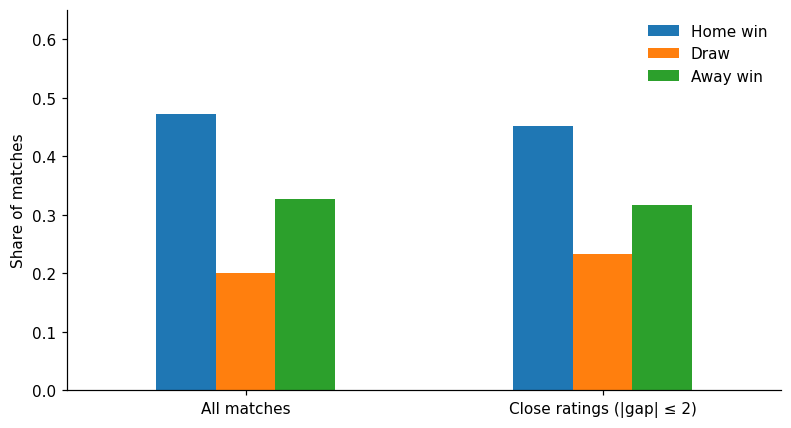

In [8]:
near = eda.loc[eda.rating_gap.abs() <= 2]
summary = pd.DataFrame({'All matches':eda.label_90min_wdl.value_counts(normalize=True),
                      'Close ratings (|gap| ≤ 2)':near.label_90min_wdl.value_counts(normalize=True)}).reindex(['H','D','A'])
print('Close-rated matches:',len(near),'/',len(eda))
display((summary*100).round(1))

fig,ax=plt.subplots(figsize=(7.3,4.0))
summary.T.plot(kind='bar',ax=ax,rot=0)
ax.set_ylabel('Share of matches')
ax.set_ylim(0,.65)
ax.legend(['Home win','Draw','Away win'],frameon=False)
savefig('01_home_advantage_close_ratings')

The nominal home-win share remains higher than the away-win share even among teams with similar EA FC overall ratings.

This motivates retaining a home/neutral context indicator alongside team-strength inputs.

### Finding 2: How does the rating gap relate to actual outcomes?

,band,n,home_win,away_win,home_low,home_high,mean_goal_diff
0,≤ -10,85,0.176,0.682,0.110,0.271,-1.494
1,"(-10, -5]",231,0.208,0.571,0.160,0.265,-0.905
2,"(-5, -2]",252,0.357,0.417,0.301,0.418,-0.171
3,"(-2, 2]",375,0.469,0.304,0.419,0.520,0.400
4,"(2, 5]",240,0.638,0.158,0.575,0.696,1.125
5,"(5, 10]",190,0.768,0.095,0.703,0.823,1.811
6,> 10,60,0.817,0.050,0.701,0.894,2.533


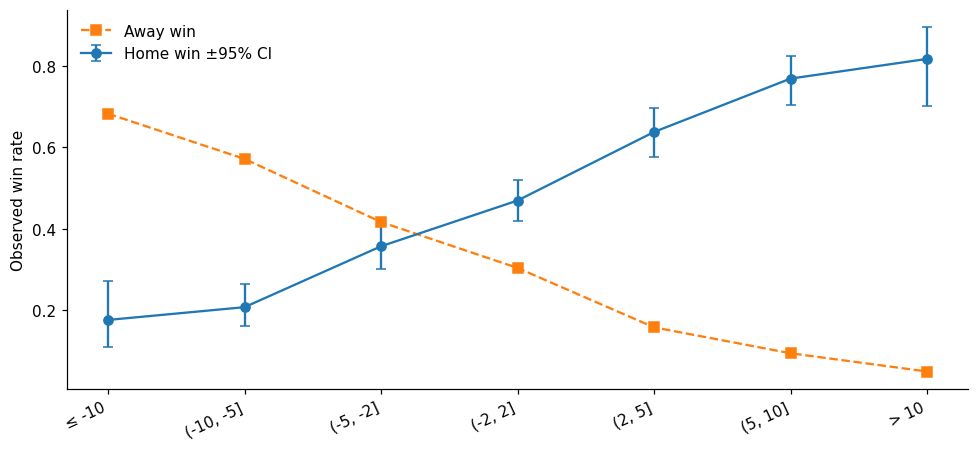

Pearson corr(rating gap, 90-minute goal difference): 0.494


In [9]:
bounds = [-np.inf, -10, -5, -2, 2, 5, 10, np.inf]
labels_gap = ['≤ -10','(-10, -5]','(-5, -2]','(-2, 2]','(2, 5]','(5, 10]','> 10']
eda['gap_band'] = pd.cut(eda.rating_gap, bins=bounds, labels=labels_gap, include_lowest=True)
rows=[]

for band, g in eda.groupby('gap_band',observed=True,sort=True):
    n = len(g)
    h = g.home_win.sum()
    a = g.away_win.sum()
    low, high = wilson_interval(h, n)
    rows.append({'band':str(band), 'n':n, 'home_win':h/n, 'away_win':a/n, 'home_low':low, 'home_high':high, 'mean_goal_diff':g.goal_diff.mean()})

gap_summary=pd.DataFrame(rows)
display(gap_summary.round(3))
gap_summary.to_csv(OUT_DIR/'tables'/'rating_gap_outcomes.csv', index=False)

fig, ax = plt.subplots(figsize=(9,4.2))
x = np.arange(len(gap_summary))
ax.errorbar(x, gap_summary.home_win, yerr=[gap_summary.home_win-gap_summary.home_low,gap_summary.home_high-gap_summary.home_win], fmt='o-', capsize=3, label='Home win ±95% CI')
ax.plot(x, gap_summary.away_win, 's--', label='Away win')
ax.set_xticks(x, gap_summary.band, rotation=25, ha='right')
ax.set_ylabel('Observed win rate')
ax.legend(frameon=False)
savefig('02_rating_gap_win_rates')
print('Pearson corr(rating gap, 90-minute goal difference):', round(eda[['rating_gap','goal_diff']].corr().iloc[0,1], 3))

The win-rate gradient across strength-gap bands suggests that relative team quality is strongly associated with match outcomes.

Ratings are predictive proxies rather than calibrated probabilities; departures from perfect symmetry motivate testing nonlinear learners and venue controls.

### Finding 3: Is the strength relationship stable across seasons?
The association between preseason-style club ratings and outcomes is not identical across seasons. This supports a strict chronological validation/test split instead of randomly splitting matches that reuse the same season-level rosters.

,n,corr_gap_goaldiff,avg_goals
season,,,
2014-15,101.0,0.524,2.812
2015-16,87.0,0.627,2.782
2016-17,107.0,0.527,3.056
2017-18,107.0,0.445,3.243
2018-19,119.0,0.435,2.882
2019-20,107.0,0.481,3.206
2020-21,107.0,0.546,2.879
2021-22,113.0,0.507,3.009
2022-23,119.0,0.481,2.891


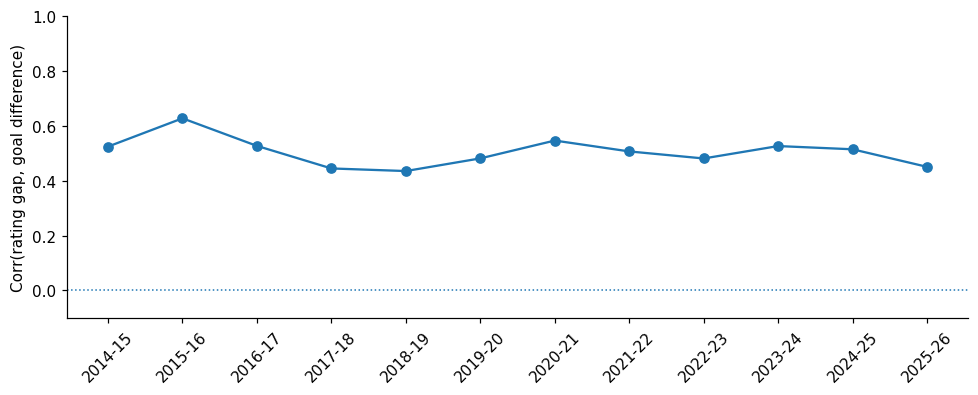

In [10]:
byseason = eda.groupby('season',sort=True).apply(lambda g:pd.Series({'n':len(g),'corr_gap_goaldiff':g[['rating_gap','goal_diff']].corr().iloc[0,1],'avg_goals':g.total_goals.mean()}),include_groups=False)
display(byseason.round(3))
byseason.to_csv(OUT_DIR/'tables'/'season_strength_stability.csv')

fig, ax = plt.subplots(figsize=(9,3.7))
ax.plot(byseason.index,byseason.corr_gap_goaldiff,marker='o')
ax.axhline(0,ls=':',lw=1)
ax.set_ylabel('Corr(rating gap, goal difference)')
ax.set_ylim(-.1,1)
ax.tick_params(axis='x',rotation=45)
savefig('03_season_strength_stability')

### Finding 4: Are goals compatible with a simple Poisson approximation?

Compare empirical total-goals frequencies against a Poisson distribution with the same mean, and report the variance-to-mean ratio.

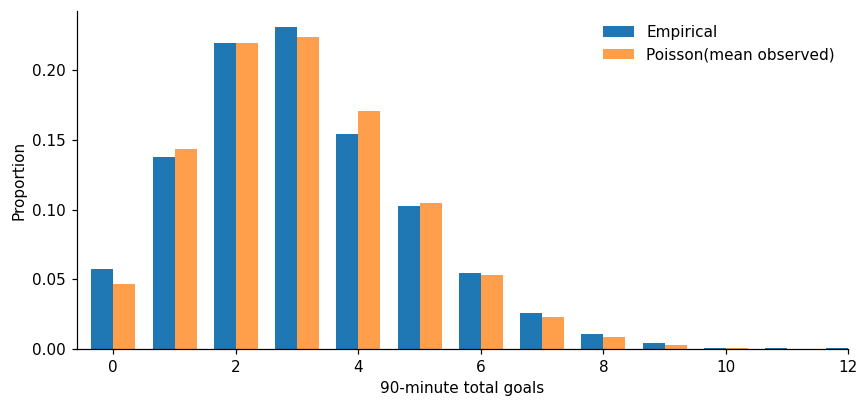

Mean: 3.057 | Variance: 3.317 | Variance/mean: 1.085


In [11]:
from scipy.stats import poisson

values = eda.total_goals.astype(int)
mu = values.mean()
var = values.var(ddof=1)

K = max(7, int(values.max()))
xs = np.arange(K+1)
obs = values.value_counts(normalize=True).reindex(xs,fill_value=0).values
expected = poisson.pmf(xs, mu)

fig, ax = plt.subplots(figsize=(8,3.8))
ax.bar(xs-0.18, obs, width=0.36, label='Empirical')
ax.bar(xs+.18, expected, width=.36, label='Poisson(mean observed)', alpha=.75)
ax.set_xlim(-.6,min(K+1,12))
ax.set_xlabel('90-minute total goals')
ax.set_ylabel('Proportion');ax.legend(frameon=False)
savefig('05_goal_distribution_poisson')

print(f'Mean: {mu:.3f} | Variance: {var:.3f} | Variance/mean: {var/mu:.3f}')

Total goals have a distribution broadly reminiscent of a Poisson count process, making home- and away-goal models a natural probabilistic baseline.

Any extra dispersion, team dependence, and score correlation will need to be evaluated using held-out log likelihood or calibration.

## Part III Broad model search across six prediction tasks

**Why:** I tested multiple targets (W/D/L, goal difference, two goal counts, home win, over 2.5 goals) and Logistic/Linear, tree-based, boosting, KNN/SVM, and MLP models. I also compared Club Only (15), Compact (93), and Full Core (753) features.

| Evidence retained | Finding | What it means |
|---|---|---|
| Initial models | Selected W/D/L methods achieved roughly 55–57% test accuracy; home-win AUC about 0.73 | Models learn some strength signal, but predictions remain difficult |
| Generalization | Full Core Logistic reached ~94.8% train accuracy but ~47.4% validation | Hundreds of player columns overfit strongly |
| Unified evaluation | Goal Difference/Two Goals had competitive probabilistic scores; Direct W/D/L was competitive on accuracy / Macro-F1 | Keep all three prediction routes as complementary baselines |
| Draw diagnosis | Validation Draw AUC ≈ 0.55; direct argmax almost never predicts draws | Probability ranking for draws is weak; do not mistake this for zero simulated draw probability |
| Decision threshold | Direct W/D/L test accuracy improved ~56.3% → 57.5% with a validation-chosen draw threshold | Threshold adjusts classification decisions, not underlying probabilities |
| Relative features | Diff and Diff + Level gave small/inconsistent changes | Relative strength is useful to test, not automatically better |

**Other experiments not retained:** repeated single-season model rankings for six tasks, exhaustive goal-model pairing, full-dimension SHAP charts, draw-threshold sweeps, and large raw-feature combinations. They were exploratory but did not establish a stable benefit over Club Only. The original notebook remains the audit trail.

In [12]:
from pathlib import Path
import warnings, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, PoissonRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import (accuracy_score, f1_score, log_loss, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score, mean_poisson_deviance,
    confusion_matrix, ConfusionMatrixDisplay, brier_score_loss)
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier, CatBoostRegressor

In [13]:
HAS_XGB = True
HAS_CAT = True

PREPARED = OUT_DIR / 'prepared' if 'OUT_DIR' in globals() else Path('analysis/eda_output/prepared')
if not PREPARED.exists() and Path('../analysis/eda_output/prepared').exists():
    PREPARED = Path('../analysis/eda_output/prepared')

RESULTS = Path('model/results')
if not Path('data').exists() and Path('../data').exists(): 
    RESULTS = Path('../model/results')
RESULTS.mkdir(parents=True, exist_ok=True)
(RESULTS/'models').mkdir(exist_ok=True)
(RESULTS/'figures').mkdir(exist_ok=True)
(RESULTS/'predictions').mkdir(exist_ok=True)

RANDOM_SEED = 42
QUICK_RUN = False
FEATURE_SETS = ['club_only', 'compact', 'full_core']
RUN_MLP = True

### 3.1 Load dataset

Use `scaled` data for Logistic/Linear Regression, KNN, SVM and MLP; use `tree` data for tree ensembles. The six target columns never enter `X`.

In [14]:
_cache = {}
def load_split(feature_set, split, scale='tree'):
    key = (feature_set, split, scale)
    if key not in _cache:
        folder = PREPARED / feature_set
        X = pd.read_csv(folder/f'X_{split}_{scale}.csv')
        meta = pd.read_csv(folder/f'y_meta_{split}.csv')
        _cache[key] = (X, meta)
    return _cache[key]

for fs in FEATURE_SETS:
    Xtr, ytr = load_split(fs,'train')
    Xva, yva = load_split(fs,'valid')
    Xte, yte = load_split(fs,'test')
    print(f'{fs:10}: {Xtr.shape[0]} train / {Xva.shape[0]} valid / {Xte.shape[0]} test, {Xtr.shape[1]} features')

TASKS = {
    'wdl': {'label':'label_90min_wdl','type':'multi','metric':'log_loss'},
    'goal_diff': {'label':'label_90min_goal_diff','type':'reg','metric':'mae'},
    'home_goals': {'label':'label_90min_home_goals','type':'count','metric':'mae'},
    'away_goals': {'label':'label_90min_away_goals','type':'count','metric':'mae'},
    'home_win': {'label':'label_90min_home_win','type':'binary','metric':'log_loss'},
    'over25': {'label':'label_90min_over25','type':'binary','metric':'log_loss'},
}

club_only : 1086 train / 173 valid / 174 test, 15 features
compact   : 1086 train / 173 valid / 174 test, 93 features
full_core : 1086 train / 173 valid / 174 test, 753 features


### 3.2 Model Runner

In [15]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import balanced_accuracy_score

# consistent class order
def encode_target(task, series):
    if task == 'wdl':
        return pd.Categorical(series, categories=['A','D','H']).codes
    return pd.to_numeric(series,errors='raise').to_numpy()

def make_models(task):
    kind=TASKS[task]['type']
    classify = kind in ('multi','binary')
    models = {}
    if classify:
        models['Dummy'] = (DummyClassifier(strategy='prior'), 'tree')
        models['Logistic'] = (LogisticRegression(max_iter=2500, random_state=RANDOM_SEED), 'scaled')
        models['DecisionTree'] = (DecisionTreeClassifier(max_depth=5, min_samples_leaf=12, random_state=RANDOM_SEED), 'tree')
        models['KNN'] = (KNeighborsClassifier(n_neighbors=25, weights='distance'), 'scaled')
        models['SVM'] = (SVC(C=1.0, probability=True, random_state=RANDOM_SEED), 'scaled')
        models['RandomForest'] = (RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=4, n_jobs=-1, random_state=RANDOM_SEED), 'tree')
        models['HistGB'] = (HistGradientBoostingClassifier(max_iter=150,max_leaf_nodes=15,l2_regularization=5,random_state=RANDOM_SEED),'tree')
        # XGB
        opts = dict(n_estimators=220,max_depth=3,learning_rate=0.04,subsample=.85,colsample_bytree=.85,reg_lambda=5,tree_method='hist',random_state=RANDOM_SEED,n_jobs=4)
        if kind == 'multi': 
            opts.update(objective='multi:softprob', num_class=3)
        else: 
            opts.update(objective='binary:logistic')
        models['XGBoost'] = (XGBClassifier(**opts), 'tree')
        # CatBoost
        opts = dict(iterations=260,depth=4,learning_rate=.04,l2_leaf_reg=5,verbose=False,random_seed=RANDOM_SEED,thread_count=4)
        models['CatBoost'] = (CatBoostClassifier(loss_function='MultiClass' if kind=='multi' else 'Logloss',**opts),'tree')
        # MLP
        models['MLP'] = (MLPClassifier(hidden_layer_sizes=(64,32), alpha=5, early_stopping=True, n_iter_no_change=15, max_iter=250, random_state=RANDOM_SEED), 'scaled')
    
    else: # Regression
        models['Dummy'] = (DummyRegressor(strategy='mean'),'tree')
        models['Linear'] = (LinearRegression(),'scaled')
        models['Ridge'] = (Ridge(alpha=50.0),'scaled')
        models['DecisionTree'] = (DecisionTreeRegressor(max_depth=5,min_samples_leaf=12,random_state=RANDOM_SEED),'tree')
        models['KNN'] = (KNeighborsRegressor(n_neighbors=25,weights='distance'),'scaled')
        models['SVR'] = (SVR(C=1.0,epsilon=.2),'scaled')
        models['RandomForest'] = (RandomForestRegressor(n_estimators=200,max_depth=10,min_samples_leaf=4,n_jobs=-1,random_state=RANDOM_SEED),'tree')
        models['HistGB'] = (HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=15,l2_regularization=5,random_state=RANDOM_SEED),'tree')
        if kind == 'count':
            models['Poisson']=(PoissonRegressor(alpha=1,max_iter=1000),'scaled')
        # XGB
        objective = 'count:poisson' if kind=='count' else 'reg:squarederror'
        models['XGBoost'] = (XGBRegressor(objective=objective,n_estimators=220,max_depth=3,learning_rate=.04,subsample=.85,colsample_bytree=.85,reg_lambda=5,tree_method='hist',n_jobs=4,random_state=RANDOM_SEED),'tree')
        # CatBoost
        models['CatBoost'] = (CatBoostRegressor(loss_function='Poisson' if kind=='count' else 'RMSE',iterations=260,depth=4,learning_rate=.04,l2_leaf_reg=5,verbose=False,random_seed=RANDOM_SEED,thread_count=4),'tree')
        # MLP
        models['MLP']=(MLPRegressor(hidden_layer_sizes=(64,32),alpha=5,early_stopping=True,n_iter_no_change=15,max_iter=250,random_state=RANDOM_SEED),'scaled')
    
    if QUICK_RUN:
        keep={'Dummy','Logistic','Linear','Ridge','Poisson','DecisionTree','RandomForest','XGBoost','CatBoost','MLP'}
        models={k:v for k,v in models.items() if k in keep}

    return models

def calculate_metrics(task,y_true, model, X):
    kind = TASKS[task]['type']
    y = np.asarray(y_true)
    if kind in ('multi','binary'):
        probs = model.predict_proba(X)
        classes = np.asarray(model.classes_, dtype=int)
        if kind == 'multi':
            fullprob = np.zeros((len(y),3))
            fullprob[:,classes] = probs
            fullprob = np.clip(fullprob, 1e-10, 1)
            fullprob /= fullprob.sum(axis=1, keepdims=True)
            pred = fullprob.argmax(axis=1)
            return {'log_loss':log_loss(y,fullprob,labels=[0,1,2]),'accuracy':accuracy_score(y,pred),
                    'macro_f1':f1_score(y,pred,average='macro',zero_division=0)}, fullprob, pred
        pos = np.flatnonzero(classes==1)
        p = probs[:,pos[0]] if len(pos) else np.zeros(len(y))
        p = np.clip(p,1e-10,1-1e-10)
        pred = (p>=.5).astype(int)
        metrics = {'log_loss':log_loss(y,np.c_[1-p,p],labels=[0,1]),
                  'accuracy':accuracy_score(y,pred),'f1':f1_score(y,pred,zero_division=0),
                  'brier':brier_score_loss(y,p)}
        metrics['roc_auc'] = roc_auc_score(y,p) if len(np.unique(y)) == 2 else np.nan
        return metrics, p, pred
    
    pred = np.asarray(model.predict(X), dtype=float)
    if kind == 'count': 
        pred = np.maximum(pred, 1e-8)
    m = {'mae':mean_absolute_error(y,pred),'rmse':np.sqrt(mean_squared_error(y,pred)), 'r2':r2_score(y,pred)}
    if kind=='count':
        m['poisson_deviance'] = mean_poisson_deviance(y,pred)

    return m, pred, pred

In [16]:
def run_task(task, feature_sets=None):
    if feature_sets is None: 
        feature_sets = FEATURE_SETS

    setting = TASKS[task]
    records, winners = [], []
    
    for fs in feature_sets:
        tr_meta = load_split(fs,'train')[1]
        va_meta = load_split(fs,'valid')[1]
        y_train = encode_target(task, tr_meta[setting['label']])
        y_valid = encode_target(task, va_meta[setting['label']])

        candidates = []
        for model_name, (est, scale) in make_models(task).items():
            X_train = load_split(fs,'train',scale)[0]
            X_valid = load_split(fs,'valid',scale)[0]
            t0 = time.time()
            try:
                fitted = clone(est).fit(X_train, y_train)
                val_metrics, probs, pred=calculate_metrics(task, y_valid, fitted, X_valid)
                item={'task':task, 'feature_set':fs, 'model':model_name, 'scale':scale, 'seconds':round(time.time()-t0,1), **val_metrics}
                records.append(item)
                candidates.append((item, fitted))
            except Exception as e:
                print(f'[Skipped] {task} / {fs} / {model_name}: {str(e)[:140]}')
        if not candidates: 
            continue

        trees = {'DecisionTree','RandomForest','HistGB','XGBoost','CatBoost'}
        tree_candidates = [(r,m) for r,m in candidates if r['model'] in trees]
        if tree_candidates:
            tree_row, tree_model = min(tree_candidates, key=lambda v: v[0][setting['metric']])
            joblib.dump({'model':tree_model,'task':task,'feature_set':fs,'scale':tree_row['scale'],
                         'columns':load_split(fs,'valid',tree_row['scale'])[0].columns.tolist()},
                         RESULTS/'models'/f'{task}_{fs}_best_tree.joblib')
            
        metric = setting['metric']
        best_row, best_model = min(candidates, key=lambda v: v[0][metric])
        X_test, test_meta = load_split(fs, 'test', best_row['scale'])
        y_test = encode_target(task, test_meta[setting['label']])
        test_scores, test_probs, test_pred = calculate_metrics(task, y_test, best_model, X_test)
        test_row={'task': task, 'feature_set': fs, 'model': best_row['model'],
                  'selection_metric': metric, 'valid_score': best_row[metric], **{f'test_{k}':v for k,v in test_scores.items()}}
        winners.append(test_row)
        filename=f'{task}_{fs}_{best_row["model"]}'
        joblib.dump({'model': best_model, 'task': task, 'feature_set': fs, 'scale': best_row['scale'],
                     'columns': X_test.columns.tolist(), 'class_names': ['A','D','H'] if task=='wdl' else None}, RESULTS/'models'/f'{filename}.joblib')
        
        out = test_meta[['match_id','season','home_team','away_team']].copy()
        out['actual'] = y_test
        if setting['type'] == 'multi':
            out[['p_away','p_draw','p_home']] = test_probs
            out['predicted'] = test_pred
        elif setting['type'] == 'binary':
            out['probability'] = test_probs
            out['predicted'] = test_pred
        else:
            out['predicted'] = test_pred

        out.to_csv(RESULTS/'predictions'/f'{filename}_test.csv',index=False)
        print(f'{task:12} {fs:10} | best {best_row["model"]:13} | valid {metric}={best_row[metric]:.4f} | test {metric}={test_scores[metric]:.4f}')

    table = pd.DataFrame(records)
    selected = pd.DataFrame(winners)
    table.to_csv(RESULTS/f'{task}_validation_all.csv',index=False)
    selected.to_csv(RESULTS/f'{task}_test_selected.csv',index=False)
    if not table.empty:
        display(table.sort_values(['feature_set',setting['metric']]).round(4))
    if not selected.empty:
        display(selected.round(4))
    return table, selected

### 3.3 Run the six prediction tasks

In [17]:
# Run the six original tasks without six near-identical code cells.
all_validation, all_selected = {}, {}
for task in ['wdl', 'goal_diff', 'home_goals', 'away_goals', 'home_win', 'over25']:
    print(f'\n=== {task} ===')
    all_validation[task], all_selected[task] = run_task(task)


=== wdl ===
wdl          club_only  | best Logistic      | valid log_loss=0.9304 | test log_loss=0.9702
wdl          compact    | best KNN           | valid log_loss=0.9309 | test log_loss=1.0754
wdl          full_core  | best CatBoost      | valid log_loss=0.9387 | test log_loss=0.9328


,task,feature_set,model,scale,seconds,log_loss,accuracy,macro_f1
1,wdl,club_only,Logistic,scaled,0.0,0.9304,0.5723,0.4312
9,wdl,club_only,MLP,scaled,0.1,0.9394,0.5780,0.4144
8,wdl,club_only,CatBoost,tree,0.3,0.9724,0.5434,0.3867
4,wdl,club_only,SVM,scaled,0.2,0.9752,0.5723,0.4077
0,wdl,club_only,Dummy,tree,0.0,1.0105,0.5087,0.2248
5,wdl,club_only,RandomForest,tree,0.3,1.0117,0.5202,0.4090
7,wdl,club_only,XGBoost,tree,0.1,1.0160,0.5376,0.4256
3,wdl,club_only,KNN,scaled,0.0,1.1071,0.5491,0.4143
6,wdl,club_only,HistGB,tree,4.4,1.2466,0.4971,0.4239
2,wdl,club_only,DecisionTree,tree,0.0,1.7579,0.5434,0.3947


,task,feature_set,model,selection_metric,valid_score,test_log_loss,test_accuracy,test_macro_f1
0,wdl,club_only,Logistic,log_loss,0.9304,0.9702,0.5632,0.4184
1,wdl,compact,KNN,log_loss,0.9309,1.0754,0.5920,0.4418
2,wdl,full_core,CatBoost,log_loss,0.9387,0.9328,0.5460,0.3874



=== goal_diff ===
goal_diff    club_only  | best Ridge         | valid mae=1.5709 | test mae=1.5897
goal_diff    compact    | best KNN           | valid mae=1.5822 | test mae=1.5678
goal_diff    full_core  | best RandomForest  | valid mae=1.5764 | test mae=1.5999


,task,feature_set,model,scale,seconds,mae,rmse,r2
2,goal_diff,club_only,Ridge,scaled,0.0,1.5709,2.0030,0.2377
1,goal_diff,club_only,Linear,scaled,0.0,1.5739,2.0085,0.2335
10,goal_diff,club_only,MLP,scaled,0.1,1.5959,2.0393,0.2098
4,goal_diff,club_only,KNN,scaled,0.0,1.6015,2.0618,0.1923
5,goal_diff,club_only,SVR,scaled,0.1,1.6234,2.0916,0.1687
9,goal_diff,club_only,CatBoost,tree,0.1,1.6287,2.0771,0.1802
8,goal_diff,club_only,XGBoost,tree,0.1,1.6520,2.1072,0.1563
6,goal_diff,club_only,RandomForest,tree,0.3,1.6792,2.1479,0.1234
7,goal_diff,club_only,HistGB,tree,0.4,1.6927,2.2075,0.0741
3,goal_diff,club_only,DecisionTree,tree,0.0,1.7446,2.1910,0.0879


,task,feature_set,model,selection_metric,valid_score,test_mae,test_rmse,test_r2
0,goal_diff,club_only,Ridge,mae,1.5709,1.5897,1.9470,0.2024
1,goal_diff,compact,KNN,mae,1.5822,1.5678,1.9471,0.2023
2,goal_diff,full_core,RandomForest,mae,1.5764,1.5999,1.9564,0.1946


... (8 outputs left out)

,task,feature_set,model,selection_metric,valid_score,test_log_loss,test_accuracy,test_f1,test_brier,test_roc_auc
0,home_win,club_only,Logistic,log_loss,0.6460,0.6191,0.7011,0.6750,0.2127,0.7340
1,home_win,compact,KNN,log_loss,0.6441,0.6249,0.6724,0.6323,0.2155,0.7258
2,home_win,full_core,RandomForest,log_loss,0.6517,0.6104,0.6897,0.6625,0.2105,0.7353



=== over25 ===
over25       club_only  | best CatBoost      | valid log_loss=0.6601 | test log_loss=0.6497
over25       compact    | best CatBoost      | valid log_loss=0.6541 | test log_loss=0.6507
over25       full_core  | best RandomForest  | valid log_loss=0.6617 | test log_loss=0.6645


,task,feature_set,model,scale,seconds,log_loss,accuracy,f1,brier,roc_auc
8,over25,club_only,CatBoost,tree,0.2,0.6601,0.5954,0.7154,0.2347,0.5603
7,over25,club_only,XGBoost,tree,0.1,0.6637,0.5723,0.6917,0.2368,0.5530
1,over25,club_only,Logistic,scaled,0.0,0.6670,0.6358,0.7529,0.2369,0.5366
5,over25,club_only,RandomForest,tree,0.3,0.6686,0.5607,0.6935,0.2393,0.5074
0,over25,club_only,Dummy,tree,0.0,0.6686,0.6243,0.7687,0.2378,0.5000
4,over25,club_only,SVM,scaled,0.2,0.6692,0.6127,0.7599,0.2381,0.5178
9,over25,club_only,MLP,scaled,0.1,0.6728,0.6012,0.7396,0.2399,0.5291
3,over25,club_only,KNN,scaled,0.0,0.6748,0.5491,0.6803,0.2410,0.5301
2,over25,club_only,DecisionTree,tree,0.0,0.7080,0.5145,0.6410,0.2585,0.4808
6,over25,club_only,HistGB,tree,0.7,0.7119,0.5318,0.6524,0.2580,0.5244


,task,feature_set,model,selection_metric,valid_score,test_log_loss,test_accuracy,test_f1,test_brier,test_roc_auc
0,over25,club_only,CatBoost,log_loss,0.6601,0.6497,0.6322,0.7557,0.2286,0.5707
1,over25,compact,CatBoost,log_loss,0.6541,0.6507,0.5862,0.7143,0.2298,0.5568
2,over25,full_core,RandomForest,log_loss,0.6617,0.6645,0.6207,0.7591,0.2359,0.5066


### 3.4 Compare models and inspect errors on validation and test set

In [18]:
summary = pd.concat([x for x in all_selected.values() if len(x)], ignore_index=True)
display(summary.round(4))

,task,feature_set,model,selection_metric,valid_score,test_log_loss,test_accuracy,test_macro_f1,test_mae,test_rmse,test_r2,test_poisson_deviance,test_f1,test_brier,test_roc_auc
0,wdl,club_only,Logistic,log_loss,0.9304,0.9702,0.5632,0.4184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,wdl,compact,KNN,log_loss,0.9309,1.0754,0.5920,0.4418,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,wdl,full_core,CatBoost,log_loss,0.9387,0.9328,0.5460,0.3874,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,goal_diff,club_only,Ridge,mae,1.5709,NaN,NaN,NaN,1.5897,1.9470,0.2024,NaN,NaN,NaN,NaN
4,goal_diff,compact,KNN,mae,1.5822,NaN,NaN,NaN,1.5678,1.9471,0.2023,NaN,NaN,NaN,NaN
5,goal_diff,full_core,RandomForest,mae,1.5764,NaN,NaN,NaN,1.5999,1.9564,0.1946,NaN,NaN,NaN,NaN
6,home_goals,club_only,Poisson,mae,1.0993,NaN,NaN,NaN,1.2075,1.5214,0.0546,1.3919,NaN,NaN,NaN
7,home_goals,compact,Poisson,mae,1.1009,NaN,NaN,NaN,1.2219,1.5485,0.0206,1.4681,NaN,NaN,NaN
8,home_goals,full_core,CatBoost,mae,1.0930,NaN,NaN,NaN,1.2267,1.5475,0.0219,1.4403,NaN,NaN,NaN
9,away_goals,club_only,SVR,mae,1.0281,NaN,NaN,NaN,0.9718,1.2752,0.1243,1.3026,NaN,NaN,NaN


### 3.5 Preliminary permutation importance

- W/D/L permutation-importance check;
- route-specific Global and Local SHAP experiments

,permutation_importance
away_club_overall,0.161519
away_club_defence,0.114524
home_club_overall,0.066839
away_club_attack,0.020160
away_club_domestic_prestige,0.016015
home_club_attack,0.014142
away_club_midfield,0.010752
away_club_international_prestige,0.009995
home_club_defence,0.009508
home_club_international_prestige,0.005004


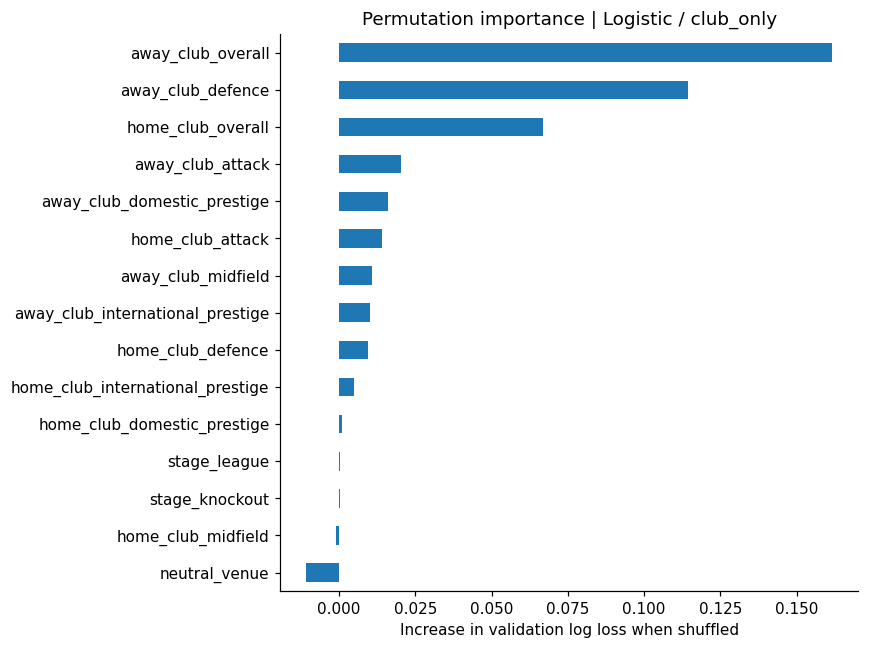

In [19]:
best = all_validation['wdl'].sort_values('log_loss').iloc[0]
bundle = joblib.load(RESULTS/'models'/f'wdl_{best.feature_set}_{best.model}.joblib')
Xval, val_meta = load_split(best.feature_set,'valid',bundle['scale'])
yval = encode_target('wdl',val_meta[TASKS['wdl']['label']])
r = permutation_importance(bundle['model'],Xval,yval,scoring='neg_log_loss', n_repeats=5,random_state=RANDOM_SEED,n_jobs=1)
imp = pd.Series(r.importances_mean,index=Xval.columns).sort_values(ascending=False)
display(imp.head(20).to_frame('permutation_importance'))

imp.to_csv(RESULTS/'wdl_permutation_importance.csv')
fig, ax = plt.subplots(figsize=(8,6));imp.head(20).sort_values().plot.barh(ax=ax)
ax.set_xlabel('Increase in validation log loss when shuffled')
ax.set_title(f'Permutation importance | {best.model} / {best.feature_set}')
fig.tight_layout()
fig.savefig(RESULTS/'figures'/'wdl_permutation_importance.png',dpi=180)
plt.show()

## Part IV Player attribute research findings

**Why:** We need to identify player information not already summarized by EA FC Club Ratings. Previously we compared player-only features, partial correlations controlling for club ratings, grouped and attribute-level permutation importance, and XGBoost importance across feature sets.

| Position | Statistical / model findings | Football-informed features retained |
|---|---|---|
| GK | Kicking, age, positioning prominent in partial correlations; positioning/physical attributes in permutation; kicking/potential frequently in XGBoost | Overall, kicking, positioning, age; reflexes reserved for an expanded sensitivity study |
| DEF | Interceptions and sprint speed important in permutation; passing and potential show residual correlation; reactions, short passing, tackles recur in XGBoost | Overall, potential, reactions, interceptions, standing tackle, short passing; *min* interception and tackle ratings |
| MID | Potential correlation; reactions, short passing important; overall and potential recurring in XGBoost | Overall, potential, reactions, short passing; *min* reactions |
| ATT | Reactions, height, age appear in permutation; finishing, reactions, potential recur in XGBoost | Overall, potential, reactions, finishing; *max* reactions and finishing |

**Interpretation:** Each position contains candidate information. However, Player Aggregates Only (Macro-AUC ~0.626) and Individual Players Only (~0.570) lagged Club Only (~0.670). Expanding position-aware features to ~199 dimensions, or adding nonlinear models, did not reliably improve validation performance. **Importance ≠ incremental predictive gain**, especially for correlated attributes and overfit models.

**Decision:** Build a compact, football-interpretable set (~23 features per team) and remove the component predictable from Club Ratings. Refit this transformation *inside each training fold* before testing whether residual player structure helps.

In [20]:
import numpy as np, pandas as pd, joblib, warnings
from pathlib import Path
from scipy.stats import norm, skellam
from sklearn.base import clone
from sklearn.metrics import (log_loss, accuracy_score, f1_score, roc_auc_score,
                             brier_score_loss, confusion_matrix)
from IPython.display import display


UNIFIED_DIR = RESULTS / 'unified_wdl'
UNIFIED_DIR.mkdir(parents=True, exist_ok=True)
(UNIFIED_DIR/'models').mkdir(exist_ok=True)

UNIFIED_FEATURES = ['club_only', 'compact', 'full_core']
EVALUATE_ALL_CANDIDATES = True
SEED = 42
DRAW_TAU_GRID = np.round(np.arange(0.1, 1.31, 0.1), 2)
DRAW_WEIGHT_GRID = [0.75, 1.0, 1.25, 1.5]

In [21]:
WDL_CLASSES = ['A', 'D', 'H']  # encoded as 0,1,2

def y_wdl(meta):
    return encode_target('wdl', meta['label_90min_wdl'])

def normalize_probs(p):
    p = np.asarray(p, dtype=float)
    p = np.maximum(p, 1e-9)
    return p / p.sum(axis=1, keepdims=True)

def wdl_metrics(y, probs):
    p = normalize_probs(probs)
    pred = np.argmax(p, axis=1)
    return dict(log_loss = log_loss(y, p, labels=[0,1,2]),
                accuracy = accuracy_score(y, pred),
                macro_f1 = f1_score(y, pred, labels=[0,1,2], average='macro', zero_division=0),
                home_win_auc = roc_auc_score((np.asarray(y)==2).astype(int), p[:,2])
                if len(np.unique(np.asarray(y) == 2)) == 2 else np.nan,
                home_win_brier = brier_score_loss((np.asarray(y) == 2).astype(int), p[:,2]))

def direct_probs(model, X):
    p = np.zeros((len(X), 3))
    for j, cl in enumerate(model.classes_):
        p[:, int(cl)] = model.predict_proba(X)[:,j]
    return normalize_probs(p)

def difference_probs(mu, sigma, tau):
    # Predicted goal difference ~ Normal(mu, sigma). A: below -tau, D: interval, H: above tau.
    mu = np.asarray(mu, dtype=float)
    sigma = max(float(sigma), 0.3)
    pa = norm.cdf((-tau-mu)/sigma)
    ph = norm.sf((tau-mu)/sigma)
    return normalize_probs(np.column_stack([pa,1-pa-ph,ph]))

def goals_probs(home_mu, away_mu, draw_weight=1.0):
    h = np.maximum(np.asarray(home_mu, dtype=float), 1e-4)
    a = np.maximum(np.asarray(away_mu, dtype=float), 1e-4)
    pa = skellam.cdf(-1,h,a)
    pd_ = skellam.pmf(0,h,a) * draw_weight
    ph = skellam.sf(0,h,a)
    return normalize_probs(np.column_stack([pa,pd_,ph]))

def candidate_models(task):
    models = make_models(task)
    if not EVALUATE_ALL_CANDIDATES:
        keep = {'Dummy','Logistic','Linear','Ridge','Poisson','XGBoost'}
        models = {k:v for k,v in models.items() if k in keep}
    return models

In [22]:
# Train and evaluate direct WDL + goal-difference candidates
all_rows = []
trained = {}

def fit_one(fs, task, model_name, estimator, scale):
    Xtr, mtr = load_split(fs, 'train', scale)
    Xva, mva = load_split(fs, 'valid', scale)
    ytr = encode_target(task, mtr[TASKS[task]['label']])
    fitted = clone(estimator)
    fitted.fit(Xtr, ytr)
    return fitted, Xtr, Xva, mtr, mva

for fs in UNIFIED_FEATURES:
    for task in ['wdl', 'goal_diff']:
        for name, (est,scale) in candidate_models(task).items():
            try:
                mdl, Xtr, Xva, mtr, mva = fit_one(fs,task,name,est,scale)
                if task == 'wdl':
                    prob = direct_probs(mdl, Xva)
                    extra = {'draw_tau':np.nan, 'sigma':np.nan}
                    route = 'Direct WDL'
                else:
                    train_resid = mtr[TASKS[task]['label']].to_numpy(float) - mdl.predict(Xtr)
                    sigma = max(np.std(train_resid,ddof=1), 0.3)
                    mu = mdl.predict(Xva)
                    options = [(log_loss(y_wdl(mva), difference_probs(mu,sigma,t),labels=[0,1,2]), t) for t in DRAW_TAU_GRID]
                    _, tau = min(options)
                    prob = difference_probs(mu, sigma, tau)
                    extra = {'draw_tau':tau, 'sigma':sigma}
                    route = 'Goal Difference'
                row={'route':route,'feature_set':fs,'model':name,
                     'scale':scale, **extra, **wdl_metrics(y_wdl(mva),prob)}
                all_rows.append(row)
                key = (route, fs, name)
                trained[key] = {'models':[mdl], 'scales':[scale], **extra}
            except Exception as exc:
                print('[skip]',fs,task,name,repr(exc)[:150])
    print('Done:',fs)

Done: club_only
Done: compact
Done: full_core


In [23]:
# Goal pairs
for fs in UNIFIED_FEATURES:
    preds, fitted = {}, {}
    valid_meta = load_split(fs,'valid')[1]
    for task in ['home_goals','away_goals']:
        for name, (est,scale) in candidate_models(task).items():
            try:
                mdl, _, Xva, _, _ = fit_one(fs, task, name, est, scale)
                preds[(task,name)] = np.maximum(np.asarray(mdl.predict(Xva),float), 1e-4)
                fitted[(task,name)] = (mdl,scale)
            except Exception as exc:
                print('[skip]',fs,task,name,repr(exc)[:150])
    n_pairs=0
    for hn in [k[1] for k in preds if k[0]=='home_goals']:
        for an in [k[1] for k in preds if k[0]=='away_goals']:
            h, a = preds[('home_goals',hn)], preds[('away_goals',an)]
            weights=[(log_loss(y_wdl(valid_meta),goals_probs(h,a,w),labels=[0,1,2]),w) for w in DRAW_WEIGHT_GRID]
            _, w = min(weights)
            prob = goals_probs(h, a, w)
            name = f'{hn} + {an}'
            row = {'route':'Two Goals','feature_set':fs,'model':name,
                 'scale':'mixed','draw_weight':w,**wdl_metrics(y_wdl(valid_meta),prob)}
            all_rows.append(row)
            trained[('Two Goals',fs,name)]={
                'models':[fitted[('home_goals',hn)][0],fitted[('away_goals',an)][0]],
                'scales':[fitted[('home_goals',hn)][1],fitted[('away_goals',an)][1]],
                'draw_weight':w}
            n_pairs += 1
    print(fs, '| goal-pairs evaluated:', n_pairs)


club_only | goal-pairs evaluated: 144
compact | goal-pairs evaluated: 144
full_core | goal-pairs evaluated: 144


In [24]:
# Compare and select on validation
val_table = pd.DataFrame(all_rows).sort_values('log_loss').reset_index(drop=True)
route_best = (val_table.sort_values('log_loss').drop_duplicates('route').reset_index(drop=True))
global_best = val_table.iloc[0]
print('Best by route (Validation):')

display(route_best[['route','feature_set','model','log_loss','accuracy','macro_f1',
                    'home_win_auc','draw_tau','draw_weight']].round(4))
print('Overall winner (Validation):')
display(val_table.head(12)[['route','feature_set','model','log_loss','accuracy',
                             'macro_f1','draw_tau','draw_weight']].round(4))

Best by route (Validation):


,route,feature_set,model,log_loss,accuracy,macro_f1,home_win_auc,draw_tau,draw_weight
0,Goal Difference,club_only,Linear,0.9122,0.5723,0.4085,0.6929,0.4,NaN
1,Two Goals,club_only,Poisson + Poisson,0.9175,0.5607,0.3986,0.6853,NaN,0.75
2,Direct WDL,club_only,Logistic,0.9304,0.5723,0.4312,0.6939,NaN,NaN


Overall winner (Validation):


,route,feature_set,model,log_loss,accuracy,macro_f1,draw_tau,draw_weight
0,Goal Difference,club_only,Linear,0.9122,0.5723,0.4085,0.4,NaN
1,Goal Difference,club_only,Ridge,0.9137,0.5723,0.4085,0.4,NaN
2,Two Goals,club_only,Poisson + Poisson,0.9175,0.5607,0.3986,NaN,0.75
3,Two Goals,club_only,Poisson + Ridge,0.9180,0.5780,0.4139,NaN,0.75
4,Two Goals,club_only,Poisson + KNN,0.9185,0.6012,0.4302,NaN,0.75
5,Two Goals,compact,KNN + XGBoost,0.9191,0.5896,0.4200,NaN,0.75
6,Two Goals,club_only,Linear + KNN,0.9197,0.5954,0.4256,NaN,0.75
7,Two Goals,club_only,Linear + Poisson,0.9199,0.5780,0.4100,NaN,0.75
8,Two Goals,club_only,Linear + Ridge,0.9200,0.5665,0.4036,NaN,0.75
9,Two Goals,club_only,Ridge + KNN,0.9201,0.5954,0.4246,NaN,0.75


In [25]:
# Test evaluation and saved predictions
selected_keys=[]
for _, r in route_best.iterrows():
    selected_keys.append((r['route'], r['feature_set'], r['model']))
selected_keys = list(dict.fromkeys(selected_keys))

test_rows = []
for route, fs, name in selected_keys:
    pack = trained[(route, fs, name)]
    xmeta = load_split(fs,'test')[1]
    actual = y_wdl(xmeta)
    if route == 'Direct WDL':
        probs = direct_probs(pack['models'][0],load_split(fs,'test',pack['scales'][0])[0])
    elif route == 'Goal Difference':
        X = load_split(fs,'test',pack['scales'][0])[0]
        probs = difference_probs(pack['models'][0].predict(X),pack['sigma'],pack['draw_tau'])
    else:
        Xh = load_split(fs,'test',pack['scales'][0])[0]
        Xa = load_split(fs,'test',pack['scales'][1])[0]
        probs = goals_probs(pack['models'][0].predict(Xh),pack['models'][1].predict(Xa),pack['draw_weight'])

    scores = wdl_metrics(actual, probs)
    test_rows.append({'route':route,'feature_set':fs,'model':name,**scores})
    pred = xmeta[['match_id','season','home_team','away_team']].copy()
    pred['actual_wdl'] = np.asarray(WDL_CLASSES)[actual]
    pred[['p_away','p_draw','p_home']] = probs
    pred['pred_wdl'] = np.asarray(WDL_CLASSES)[probs.argmax(axis=1)]
    slug = route.lower().replace(' ','_')
    pred.to_csv(UNIFIED_DIR/f'test_predictions_{slug}.csv',index=False)
    joblib.dump({'route':route, 'feature_set':fs, 'model_name':name, **pack}, UNIFIED_DIR/'models'/f'{slug}_selected.joblib')

test_table=pd.DataFrame(test_rows)
display(test_table.round(4))

,route,feature_set,model,log_loss,accuracy,macro_f1,home_win_auc,home_win_brier
0,Goal Difference,club_only,Linear,0.9572,0.5460,0.3876,0.7275,0.2118
1,Two Goals,club_only,Poisson + Poisson,0.9530,0.5575,0.3948,0.7271,0.2131
2,Direct WDL,club_only,Logistic,0.9702,0.5632,0.4184,0.7345,0.2124


## Part V Selected position features and club-residualization

**Goal:** Test whether a player's position-specific ability *above/below what the club rating predicts* improves match outcomes. For each fold, a regularized Ridge regression learns `Player feature ~ Club features` on the training seasons only; the residual is `observed player feature − fitted player feature`. No match labels are used in this step.

Compare **Club Only**, **Club + raw selected players**, **Club + residualized players**, and **Club + residualized home-away differences**. The original Club features stay in all combined experiments.

In [26]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge, PoissonRegressor
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss
from scipy.stats import norm, skellam
from IPython.display import display

RESEARCH_OUT = Path('model/results/focused_position_study')
RESEARCH_OUT.mkdir(parents=True, exist_ok=True)
MATCH = full.copy()  # Loaded in Part I
CLUB_COLS = feature_sets['club_only']
SLOTS = {'GK':['gk1'], 'DEF':[f'def{i}' for i in range(1,5)],
         'MID':[f'mid{i}' for i in range(1,4)],
         'ATT':[f'att{i}' for i in range(1,4)]}
CORE = {
    'GK': ['overall','goalkeeping_kicking','goalkeeping_positioning','age'],
    'DEF': ['overall','potential','movement_reactions','mentality_interceptions',
            'defending_standing_tackle','attacking_short_passing'],
    'MID': ['overall','potential','movement_reactions','attacking_short_passing'],
    'ATT': ['overall','potential','movement_reactions','attacking_finishing']
}
EXTRAS = {'DEF': {'mentality_interceptions':'min', 'defending_standing_tackle':'min'},
          'MID': {'movement_reactions':'min'},
          'ATT': {'movement_reactions':'max','attacking_finishing':'max'}}

In [27]:
# build compact position-aware statistics from 22 individual players
def make_position_features(data):
    feats = {}
    for side in ['home','away']:
        for position, slots in SLOTS.items():
            for attr in CORE[position]:
                cols = [f'{side}_{slot}_{attr}' for slot in slots]
                missing = [c for c in cols if c not in data.columns]
                if missing:
                    raise KeyError(f'Missing player columns: {missing}')
                values = data[cols].apply(pd.to_numeric, errors='coerce')
                base = f'{side}_{position.lower()}_{attr}'
                feats[base+'_mean'] = values.mean(axis=1)
                extra = EXTRAS.get(position,{}).get(attr)
                if extra == 'min': feats[base+'_min'] = values.min(axis=1)
                if extra == 'max': feats[base+'_max'] = values.max(axis=1)
    return pd.DataFrame(feats, index=data.index)

pos_data = make_position_features(MATCH)
club_data = MATCH[CLUB_COLS].apply(pd.to_numeric,errors='coerce')
assert len(pos_data) == len(MATCH) and pos_data.columns.is_unique
print('Position features:',pos_data.shape[1], 'Club features:',club_data.shape[1])
display(pos_data.head(2))

Position features: 46 Club features: 15


,home_gk_overall_mean,home_gk_goalkeeping_kicking_mean,home_gk_goalkeeping_positioning_mean,home_gk_age_mean,home_def_overall_mean,home_def_potential_mean,home_def_movement_reactions_mean,home_def_mentality_interceptions_mean,home_def_mentality_interceptions_min,home_def_defending_standing_tackle_mean,...,away_mid_potential_mean,away_mid_movement_reactions_mean,away_mid_movement_reactions_min,away_mid_attacking_short_passing_mean,away_att_overall_mean,away_att_potential_mean,away_att_movement_reactions_mean,away_att_movement_reactions_max,away_att_attacking_finishing_mean,away_att_attacking_finishing_max
0,77.0,81.0,75.0,31.0,76.5,80.0,72.50,79.0,75.0,77.5,...,81.333333,80.666667,78.0,82.333333,78.000000,81.333333,79.333333,85.0,82.333333,88.0
1,83.0,61.0,85.0,33.0,83.0,84.5,81.75,81.5,74.0,86.0,...,85.666667,84.333333,81.0,86.000000,77.333333,82.000000,75.666667,81.0,76.666667,86.0


In [28]:
# Residualize selected player features using Club Ratings only.
def make_fold_features(train_mask, valid_mask, kind, residual_alpha=10.0):
    club_train = club_data.loc[train_mask].copy()
    club_valid = club_data.loc[valid_mask].copy()
    if kind == 'club':
        return club_train, club_valid

    # Player features may contain missing data; remove only all-empty train columns.
    usable = pos_data.columns[pos_data.loc[train_mask].notna().any()].tolist()
    player_train = pos_data.loc[train_mask,usable]
    player_valid = pos_data.loc[valid_mask,usable]

    if kind == 'raw':
        return (pd.concat([club_train,player_train],axis=1),
                pd.concat([club_valid,player_valid],axis=1))

    # Learn the expected player statistics conditional on the club profile.
    club_rating_cols = [c for c in CLUB_COLS if '_club_' in c]
    club_imputer = SimpleImputer(strategy='median')
    ctrain = club_imputer.fit_transform(club_train[club_rating_cols])
    cvalid = club_imputer.transform(club_valid[club_rating_cols])
    standard = StandardScaler().fit(ctrain)
    ctrain = standard.transform(ctrain)
    cvalid = standard.transform(cvalid)

    player_imputer = SimpleImputer(strategy='median')
    ptrain = player_imputer.fit_transform(player_train)
    pvalid = player_imputer.transform(player_valid)

    reg = Ridge(alpha=residual_alpha).fit(ctrain,ptrain)
    train_resid = pd.DataFrame(ptrain-reg.predict(ctrain),
                               columns=usable,index=player_train.index)
    valid_resid = pd.DataFrame(pvalid-reg.predict(cvalid),
                               columns=usable,index=player_valid.index)
    train_resid = train_resid.add_prefix('resid_')
    valid_resid = valid_resid.add_prefix('resid_')

    if kind == 'residual_diff':
        def to_diff(resid):
            out = {}
            for c in resid.columns:
                if c.startswith('resid_home_'):
                    other = 'resid_away_'+c[len('resid_home_'):]
                    if other in resid:
                        out['diff_'+c[len('resid_home_'):]] = resid[c]-resid[other]
            return pd.DataFrame(out,index=resid.index)
        train_resid,valid_resid = to_diff(train_resid),to_diff(valid_resid)

    return (pd.concat([club_train,train_resid],axis=1),
            pd.concat([club_valid,valid_resid],axis=1))

train_mask = MATCH.season.isin(train_seasons)
valid_mask = MATCH.season.eq('2024-25')
for name in ['club','raw','residual','residual_diff']:
    a,b=make_fold_features(train_mask,valid_mask,name)
    print(f'{name:15s} train {a.shape}, validation {b.shape}')

club            train (1086, 15), validation (173, 15)
raw             train (1086, 61), validation (173, 61)
residual        train (1086, 61), validation (173, 61)
residual_diff   train (1086, 38), validation (173, 38)


## Part VI Rolling-season validation

**Why:** A single season (2024–25; 173 matched fixtures) is too small and has already been repeatedly explored. We therefore compare the same configurations over several future seasons, always training only on earlier seasons. This is a *new exploratory robustness check*, not a fresh untouched test set.

**Three routes:** Direct W/D/L Logistic or XGBoost; Goal Difference Ridge; Two Goals Poisson + Poisson. Model hyperparameters are fixed initially so that the feature comparison is interpretable. W/D/L metrics include Accuracy, Macro-F1, OvR Macro-AUC and Log Loss. The goal routes produce W/D/L probabilities without tuning draw weights or thresholds on the evaluation season.

In [29]:
# Prediction routes and common evaluation metrics
try:
    from xgboost import XGBClassifier
    USE_XGB = True
except ImportError:
    USE_XGB = False
    print('XGBoost unavailable; run: pip install xgboost')

CLASS_ORDER = ['A','D','H']

def score_wdl(y_true, probabilities):
    p=np.asarray(probabilities,dtype=float)
    p=np.clip(p,1e-9,1)
    p/=p.sum(axis=1,keepdims=True)
    hard=np.asarray(CLASS_ORDER)[p.argmax(axis=1)]
    out={'accuracy':accuracy_score(y_true,hard),
         'macro_f1':f1_score(y_true,hard,labels=CLASS_ORDER,average='macro',zero_division=0),
         'log_loss':log_loss(y_true,p,labels=CLASS_ORDER)}
    try:
        out['macro_auc']=roc_auc_score(y_true,p,labels=CLASS_ORDER,
                                         multi_class='ovr',average='macro')
    except ValueError:
        out['macro_auc']=np.nan
    return out

def goal_diff_probs(mu,sigma):
    # Approximation: each integer goal difference is a unit-width bin.
    sigma=max(float(sigma),0.5)
    pa=norm.cdf(-0.5,loc=mu,scale=sigma)
    ph=norm.sf(0.5,loc=mu,scale=sigma)
    return np.column_stack([pa,1-pa-ph,ph])

def two_goal_probs(mu_h,mu_a):
    mh=np.clip(np.asarray(mu_h),0.01,30)
    ma=np.clip(np.asarray(mu_a),0.01,30)
    pa=skellam.cdf(-1,mh,ma)
    pd_=skellam.pmf(0,mh,ma)
    return np.column_stack([pa,pd_,1-pa-pd_])

def make_estimator(route):
    if route=='WDL Logistic':
        return LogisticRegression(C=0.1,max_iter=3000,random_state=42)
    if route=='WDL XGBoost':
        return XGBClassifier(n_estimators=180,max_depth=3,learning_rate=0.04,
            reg_lambda=10,subsample=0.8,colsample_bytree=0.8,
            objective='multi:softprob',num_class=3,n_jobs=4,random_state=42)
    if route=='Goal Difference Ridge':return Ridge(alpha=10.0)
    if route=='Two Goals Poisson':return PoissonRegressor(alpha=1.0,max_iter=1000)
    raise KeyError(route)

def train_and_predict(route,xtrain,xvalid,train_rows):
    # Numeric preprocessing is fitted on the training fold only.
    base = make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),make_estimator(route))

    if route == 'WDL Logistic':
        base.fit(xtrain, train_rows.label_90min_wdl)
        return base.predict_proba(xvalid)[:,[list(base[-1].classes_).index(k) for k in CLASS_ORDER]]
    
    if route == 'WDL XGBoost':
        base.fit(xtrain, train_rows.label_90min_wdl.map({'A':0,'D':1,'H':2}))
        return base.predict_proba(xvalid)
    
    if route == 'Goal Difference Ridge':
        base.fit(xtrain,train_rows.label_90min_goal_diff)
        sigma = np.std(train_rows.label_90min_goal_diff.to_numpy() - base.predict(xtrain),ddof=1)
        return goal_diff_probs(base.predict(xvalid),sigma)
    
    if route == 'Two Goals Poisson':
        h = clone(base).fit(xtrain,train_rows.label_90min_home_goals)
        a = clone(base).fit(xtrain,train_rows.label_90min_away_goals)
        return two_goal_probs(h.predict(xvalid),a.predict(xvalid))

In [30]:
# Rolling evaluation: keep each target year strictly after its training years
FOLD_YEARS=[2021,2022,2023,2024]
FEATURE_VARIANTS=['club','raw','residual','residual_diff']
ROUTES=['WDL Logistic','Goal Difference Ridge','Two Goals Poisson']
if USE_XGB: ROUTES.insert(1,'WDL XGBoost')

season_start=MATCH['season'].str.slice(0,4).astype(int)
rolling_rows=[]
for holdout in FOLD_YEARS:
    tr=season_start.lt(holdout)
    va=season_start.eq(holdout)
    if tr.sum()<200 or va.sum()<10:continue
    print(f'Holdout {holdout}-{str(holdout+1)[-2:]}: train={tr.sum()}, valid={va.sum()}')
    for variant in FEATURE_VARIANTS:
        Xtr,Xva=make_fold_features(tr,va,variant)
        # Drop fold-constant columns. No look at validation target or distribution.
        keep=[c for c in Xtr if Xtr[c].dropna().nunique()>1]
        Xtr=Xtr[keep].replace([np.inf,-np.inf],np.nan)
        Xva=Xva[keep].replace([np.inf,-np.inf],np.nan)
        for route in ROUTES:
            try:
                p=train_and_predict(route,Xtr,Xva,MATCH.loc[tr])
                metrics=score_wdl(MATCH.loc[va,'label_90min_wdl'],p)
                rolling_rows.append({'season':f'{holdout}-{str(holdout+1)[-2:]}',
                    'variant':variant,'route':route,'n_features':len(keep),
                    'n_valid':int(va.sum()),**metrics})
            except Exception as ex:
                print('FAILED',holdout,variant,route,str(ex)[:180])
rolling=pd.DataFrame(rolling_rows)
rolling.to_csv(RESEARCH_OUT/'rolling_validation_all.csv',index=False)
print('Completed:',len(rolling),'fold-model combinations')
display(rolling.head().round(4))

Holdout 2021-22: train=735, valid=113
Holdout 2022-23: train=848, valid=119
Holdout 2023-24: train=967, valid=119
Holdout 2024-25: train=1086, valid=173
Completed: 64 fold-model combinations


,season,variant,route,n_features,n_valid,accuracy,macro_f1,log_loss,macro_auc
0,2021-22,club,WDL Logistic,15,113,0.5929,0.4349,0.9246,0.6730
1,2021-22,club,WDL XGBoost,15,113,0.5487,0.4029,0.9873,0.6266
2,2021-22,club,Goal Difference Ridge,15,113,0.5841,0.4261,0.9256,0.6840
3,2021-22,club,Two Goals Poisson,15,113,0.5841,0.4265,0.9287,0.6936
4,2021-22,raw,WDL Logistic,61,113,0.6018,0.4476,0.9578,0.6787


In [33]:
# Average across held-out seasons; compare each feature variant to Club Only
metrics=['accuracy','macro_f1','macro_auc','log_loss']
summary=(rolling.groupby(['route','variant'],as_index=False)
         .agg(**{m:(m,'mean') for m in metrics},
              valid_seasons=('season','nunique'),
              matches=('n_valid','sum')))
base=summary[summary.variant.eq('club')].set_index('route')
for m in ['accuracy','macro_f1','macro_auc']:
    summary['delta_'+m]=summary.apply(lambda r:r[m]-base.loc[r.route,m],axis=1)
summary['delta_log_loss']=summary.apply(lambda r:r.log_loss-base.loc[r.route,'log_loss'],axis=1)
summary=summary.sort_values(['route','macro_auc'],ascending=[True,False])
display(summary.round(4))
summary.to_csv(RESEARCH_OUT/'rolling_validation_summary.csv',index=False)

,route,variant,accuracy,macro_f1,macro_auc,log_loss,valid_seasons,matches,delta_accuracy,delta_macro_f1,delta_macro_auc,delta_log_loss
0,Goal Difference Ridge,club,0.5727,0.4163,0.6822,0.9296,4,524,0.0000,0.0000,0.0000,0.0000
3,Goal Difference Ridge,residual_diff,0.5755,0.4190,0.6786,0.9423,4,524,0.0028,0.0027,-0.0035,0.0127
1,Goal Difference Ridge,raw,0.5570,0.4070,0.6672,0.9620,4,524,-0.0157,-0.0093,-0.0149,0.0324
2,Goal Difference Ridge,residual,0.5519,0.4036,0.6624,0.9718,4,524,-0.0208,-0.0128,-0.0198,0.0422
4,Two Goals Poisson,club,0.5677,0.4114,0.6871,0.9309,4,524,0.0000,0.0000,0.0000,0.0000
7,Two Goals Poisson,residual_diff,0.5783,0.4201,0.6830,0.9324,4,524,0.0106,0.0087,-0.0041,0.0015
5,Two Goals Poisson,raw,0.5660,0.4131,0.6802,0.9321,4,524,-0.0017,0.0017,-0.0069,0.0012
6,Two Goals Poisson,residual,0.5698,0.4168,0.6751,0.9451,4,524,0.0021,0.0054,-0.0120,0.0141
8,WDL Logistic,club,0.5693,0.4156,0.6772,0.9324,4,524,0.0000,0.0000,0.0000,0.0000
11,WDL Logistic,residual_diff,0.5691,0.4321,0.6661,0.9648,4,524,-0.0001,0.0166,-0.0111,0.0323


In [32]:
# Paired season-by-season differences vs Club Only (no test-set tuning)
paired=rolling.pivot(index=['season','route'],columns='variant',values='macro_auc')
for v in ['raw','residual','residual_diff']:
    if v in paired.columns:
        paired[v+'_minus_club']=paired[v]-paired['club']
display(paired.round(4))
paired.to_csv(RESEARCH_OUT/'rolling_paired_auc.csv')

# Optional: examine the best robust configuration, not the single best season.
for route,g in summary.groupby('route'):
    best=g.sort_values(['macro_auc','accuracy'],ascending=False).iloc[0]
    print(f'{route}: {best.variant} | mean AUC={best.macro_auc:.3f}, '
          f'mean accuracy={best.accuracy:.3f}, delta AUC={best.delta_macro_auc:+.3f}')

variant                          club     raw  residual  residual_diff  \
season  route                                                            
2021-22 Goal Difference Ridge  0.6840  0.6706    0.6637         0.7035   
        Two Goals Poisson      0.6936  0.6978    0.6974         0.7090   
        WDL Logistic           0.6730  0.6787    0.6384         0.6442   
        WDL XGBoost            0.6266  0.6307    0.6533         0.6366   
2022-23 Goal Difference Ridge  0.6533  0.6641    0.6569         0.6907   
        Two Goals Poisson      0.6733  0.6824    0.6929         0.7095   
        WDL Logistic           0.6845  0.6920    0.6857         0.7307   
        WDL XGBoost            0.6814  0.6895    0.7117         0.6853   
2023-24 Goal Difference Ridge  0.7246  0.6941    0.6895         0.6846   
        Two Goals Poisson      0.7199  0.6970    0.6715         0.6804   
        WDL Logistic           0.6813  0.6435    0.6331         0.6473   
        WDL XGBoost            0.6737  0.6623    0.6871         0.6473   
2024-25 Goal Difference Ridge  0.6668  0.6400    0.6392         0.6357   
        Two Goals Poisson      0.6617  0.6434    0.6387         0.6330   
        WDL Logistic           0.6701  0.6329    0.6134         0.6423   
        WDL XGBoost            0.6028  0.6016    0.6135         0.6174   

variant                        raw_minus_club  residual_minus_club  \
season  route                                                        
2021-22 Goal Difference Ridge         -0.0133              -0.0203   
        Two Goals Poisson              0.0043               0.0039   
        WDL Logistic                   0.0057              -0.0346   
        WDL XGBoost                    0.0041               0.0268   
2022-23 Goal Difference Ridge          0.0108               0.0037   
        Two Goals Poisson              0.0091               0.0195   
        WDL Logistic                   0.0074               0.0012   
        WDL XGBoost                    0.0082               0.0303   
2023-24 Goal Difference Ridge         -0.0305              -0.0350   
        Two Goals Poisson             -0.0229              -0.0484   
        WDL Logistic                  -0.0378              -0.0481   
        WDL XGBoost                   -0.0114               0.0134   
2024-25 Goal Difference Ridge         -0.0268              -0.0276   
        Two Goals Poisson             -0.0183              -0.0230   
        WDL Logistic                  -0.0372              -0.0567   
        WDL XGBoost                   -0.0012               0.0106   

variant                        residual_diff_minus_club  
season  route                                            
2021-22 Goal Difference Ridge                    0.0195  
        Two Goals Poisson                        0.0154  
        WDL Logistic                            -0.0289  
        WDL XGBoost                              0.0101  
2022-23 Goal Difference Ridge                    0.0374  
        Two Goals Poisson                        0.0362  
        WDL Logistic                             0.0462  
        WDL XGBoost                              0.0039  
2023-24 Goal Difference Ridge                   -0.0400  
        Two Goals Poisson                       -0.0395  
        WDL Logistic                            -0.0339  
        WDL XGBoost                             -0.0264  
2024-25 Goal Difference Ridge                   -0.0311  
        Two Goals Poisson                       -0.0287  
        WDL Logistic                            -0.0278  
        WDL XGBoost                              0.0146

Goal Difference Ridge: club | mean AUC=0.682, mean accuracy=0.573, delta AUC=+0.000
Two Goals Poisson: club | mean AUC=0.687, mean accuracy=0.568, delta AUC=+0.000
WDL Logistic: club | mean AUC=0.677, mean accuracy=0.569, delta AUC=+0.000
WDL XGBoost: residual | mean AUC=0.666, mean accuracy=0.580, delta AUC=+0.020


## Part VII Decision rules after rolling validation

| Evidence across held-out seasons | Modeling decision |
|---|---|
| Position-aware features add value across several years | Consider them only where gains persist |
| Raw player features outperform residualized features | Keep interpretable raw player features; do not assume residualization helps |
| Gain only in one season or one metric | Reject as an unstable enhancement |
| Larger feature sets show no consistent benefit | Preserve Club Only and compact player-feature baselines |

**Chosen strategy:** use four rolling validation seasons for feature/model selection, then refit through 2024–25 and evaluate exactly once on 2025–26. Player attributes can matter *inside a model* without showing incremental out-of-time predictive gains. The XI is estimated from season rosters rather than observed match-day lineups.

**Workflow:** rolling-season model selection → train on 2014–15 through 2024–25 → evaluate 2025–26 → global SHAP → local SHAP for selected matches.

**Note:** Club Only is retained as a reference, while the final explanation models are selected from feature sets containing player information. The 2025–26 test season has previously been inspected and is not a fully untouched blind test.

In [34]:
import json
import warnings
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from catboost import CatBoostClassifier, CatBoostRegressor
from scipy.stats import norm, skellam
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, PoissonRegressor, Ridge
from sklearn.metrics import accuracy_score, f1_score, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

ORDER = ['A', 'D', 'H']
POSITION_SLOTS = {
    'GK': ['gk1'],
    'DEF': [f'def{i}' for i in range(1, 5)],
    'MID': [f'mid{i}' for i in range(1, 4)],
    'ATT': [f'att{i}' for i in range(1, 4)]
}
POSITION_ATTRS = {
    'GK': ['overall', 'goalkeeping_kicking', 'goalkeeping_positioning', 'age'],
    'DEF': ['overall', 'potential', 'movement_reactions', 'mentality_interceptions',
            'defending_standing_tackle', 'attacking_short_passing'],
    'MID': ['overall', 'potential', 'movement_reactions', 'attacking_short_passing'],
    'ATT': ['overall', 'potential', 'movement_reactions', 'attacking_finishing']
}
EXTRA_STATS = {
    'DEF': {'mentality_interceptions': 'min', 'defending_standing_tackle': 'min'},
    'MID': {'movement_reactions': 'min'},
    'ATT': {'movement_reactions': 'max', 'attacking_finishing': 'max'}
}
CASE_REQUESTS = [
    ('Real Madrid vs Arsenal', '2024-25', '2025-04-16', 'Real Madrid', 'Arsenal'),
    ('Aston Villa vs PSG', '2024-25', '2025-04-15', 'Aston Villa', 'Paris Saint-Germain'),
    ('Inter vs Bodo/Glimt', '2025-26', '2026-02-24', 'Internazionale', 'Bod'),
    ('Bayern vs Real Madrid', '2025-26', '2026-04-15', 'Bayern', 'Real Madrid'),
    ('PSG vs Arsenal', '2025-26', '2026-05-30', 'Paris Saint-Germain', 'Arsenal')
]

In [35]:
def club_columns(data):
    attrs = ['overall', 'attack', 'midfield', 'defence', 'domestic_prestige', 'international_prestige']
    cols = [f'{side}_club_{attr}' for side in ['home', 'away'] for attr in attrs]
    cols += ['neutral_venue', 'stage_league', 'stage_knockout']
    missing = [col for col in cols if col not in data.columns]
    if missing:
        raise KeyError(f'Missing Club features: {missing}')
    return cols


def build_position_features(data):
    out = {}
    for side in ['home', 'away']:
        for position, slots in POSITION_SLOTS.items():
            for attr in POSITION_ATTRS[position]:
                cols = [f'{side}_{slot}_{attr}' for slot in slots]
                missing = [col for col in cols if col not in data.columns]
                if missing:
                    raise KeyError(f'Missing Player features: {missing}')

                values = data[cols].apply(pd.to_numeric, errors='coerce')
                key = f'{side}_{position.lower()}_{attr}'
                out[f'{key}_mean'] = values.mean(axis=1)

                extra = EXTRA_STATS.get(position, {}).get(attr)
                if extra == 'min':
                    out[f'{key}_min'] = values.min(axis=1)
                elif extra == 'max':
                    out[f'{key}_max'] = values.max(axis=1)

    return pd.DataFrame(out, index=data.index)


def feature_groups(data):
    club = data[club_columns(data)].apply(pd.to_numeric, errors='coerce')
    position = build_position_features(data)
    defence = position.filter(regex=r'^(home|away)_def_')

    # Club+DEF, Club+Position Core and prior Compact player aggregates.
    compact_cols = [col for col in data if col.startswith(
        ('home_xi_', 'away_xi_', 'home_bench_', 'away_bench_')
    )]
    compact = data[compact_cols].apply(pd.to_numeric, errors='coerce')

    return {
        'club_only': club,
        'club_def': pd.concat([club, defence], axis=1),
        'club_position_core': pd.concat([club, position], axis=1),
        'club_compact': pd.concat([club, compact], axis=1)
    }


## Model definitions and common evaluation

Each regression route is converted to W/D/L probabilities. Draw-decision thresholds are chosen only on historical rolling predictions.

In [36]:
def make_estimator(route, algorithm, quick=False):
    if route == 'WDL':
        if algorithm == 'Logistic':
            model = LogisticRegression(C=0.1, max_iter=2500, random_state=42)
        elif algorithm == 'XGBoost':
            model = XGBClassifier(n_estimators=90 if quick else 180, max_depth=3,
                learning_rate=0.04, subsample=0.8, colsample_bytree=0.8,
                reg_lambda=10, objective='multi:softprob', num_class=3,
                n_jobs=4, random_state=42)
        elif algorithm == 'CatBoost':
            model = CatBoostClassifier(iterations=100 if quick else 250, depth=4,
                learning_rate=0.04, l2_leaf_reg=10, verbose=False,
                thread_count=4, random_seed=42, loss_function='MultiClass')
        else:
            raise ValueError(algorithm)
        
    elif route == 'Goal Difference':
        if algorithm == 'Ridge':
            model = Ridge(alpha=10)

        elif algorithm == 'RandomForest':
            model = RandomForestRegressor(n_estimators=100 if quick else 200,
                max_depth=5, min_samples_leaf=8, random_state=42, n_jobs=-1)
            
        elif algorithm == 'CatBoost':
            model = CatBoostRegressor(iterations=100 if quick else 250, depth=4,
                learning_rate=0.04, l2_leaf_reg=10, verbose=False,
                thread_count=4, random_seed=42)
        else:
            raise ValueError(algorithm)
    else:
        if algorithm == 'Poisson':
            model = PoissonRegressor(alpha=1.0, max_iter=1500)

        elif algorithm == 'RandomForest':
            model = RandomForestRegressor(n_estimators=100 if quick else 200,
                max_depth=5, min_samples_leaf=8, random_state=42, n_jobs=-1)
            
        elif algorithm == 'CatBoost':
            model = CatBoostRegressor(iterations=100 if quick else 250, depth=4,
                learning_rate=0.04, l2_leaf_reg=10, verbose=False,
                thread_count=4, random_seed=42)
        else:
            raise ValueError(algorithm)

    steps = [SimpleImputer(strategy='median')]
    if algorithm in ('Logistic', 'Ridge', 'Poisson'):
        steps.append(StandardScaler())
    steps.append(model)
    return make_pipeline(*steps)

ALGORITHMS = {
    'WDL': ['Logistic', 'XGBoost', 'CatBoost'],
    'Goal Difference': ['Ridge', 'RandomForest', 'CatBoost'],
    'Two Goals': ['Poisson', 'RandomForest', 'CatBoost']
}


In [37]:
def fit_bundle(route, algo, X, data, quick=False):
    if route == 'Two Goals':
        models = {}
        for target, col in [('home', 'label_90min_home_goals'), ('away', 'label_90min_away_goals')]:
            model = make_estimator(route, algo, quick)
            model.fit(X, data[col].to_numpy(dtype=float))
            models[target] = model
        return {'route': route, 'algo': algo, 'models': models}

    model = make_estimator(route, algo, quick)
    if route == 'WDL':
        y = data['label_90min_wdl'].map({'A': 0, 'D': 1, 'H': 2})
    else:
        y = data['label_90min_goal_diff'].astype(float)
    model.fit(X, y)
    bundle = {'route': route, 'algo': algo, 'models': {'main': model}}

    if route == 'Goal Difference':
        residual = y.to_numpy() - model.predict(X)
        bundle['sigma'] = max(float(np.std(residual, ddof=1)), 0.5)
    return bundle


def predict_bundle(bundle, X):
    route, models = bundle['route'], bundle['models']
    if route == 'WDL':
        p = models['main'].predict_proba(X)
        # All folds must include each of A, D, H.
        indices = [list(models['main'][-1].classes_).index(v) for v in [0, 1, 2]]
        return p[:, indices], None
    if route == 'Goal Difference':
        mu = models['main'].predict(X)
        sigma = bundle['sigma']
        p_away = norm.cdf(-0.5, loc=mu, scale=sigma)
        p_home = norm.sf(0.5, loc=mu, scale=sigma)
        return np.column_stack([p_away, 1 - p_away - p_home, p_home]), mu

    home = np.clip(models['home'].predict(X), 0.01, 30)
    away = np.clip(models['away'].predict(X), 0.01, 30)
    p_away = skellam.cdf(-1, home, away)
    p_draw = skellam.pmf(0, home, away)
    return np.column_stack([p_away, p_draw, 1 - p_away - p_draw]), (home, away)


def evaluate(y, probs, hard=None):
    probs = np.clip(probs, 1e-9, 1)
    probs = probs / probs.sum(axis=1, keepdims=True)
    if hard is None:
        hard = np.array(ORDER)[probs.argmax(axis=1)]

    metrics = {
        'accuracy': accuracy_score(y, hard),
        'macro_f1': f1_score(y, hard, labels=ORDER, average='macro', zero_division=0),
        'log_loss': log_loss(y, probs, labels=ORDER),
    }
    try:
        metrics['macro_auc'] = roc_auc_score(y, probs, labels=ORDER, multi_class='ovr', average='macro')
    except ValueError:
        metrics['macro_auc'] = np.nan
    return metrics


def decision_labels(route, p, raw, threshold):
    if route == 'WDL':
        return np.array(ORDER)[p.argmax(axis=1)]
    if route == 'Goal Difference':
        return np.where(raw > threshold, 'H', np.where(raw < -threshold, 'A', 'D'))
    return np.where(p[:, 1] >= threshold, 'D', np.where(p[:, 2] >= p[:, 0], 'H', 'A'))


def choose_threshold(route, probs, raw, y):
    if route == 'WDL':
        return None

    grid = np.arange(0, 1.01, 0.05) if route == 'Goal Difference' else np.arange(0.10, 0.401, 0.01)
    candidates = []
    for threshold in grid:
        pred = decision_labels(route, probs, raw, float(threshold))
        acc = accuracy_score(y, pred)
        f1 = f1_score(y, pred, labels=ORDER, average='macro', zero_division=0)
        candidates.append((0.75 * acc + 0.25 * f1, acc, f1, float(threshold)))
    return max(candidates)[-1]


def clean_frames(Xtr, Xva):
    Xtr = Xtr.apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
    Xva = Xva.apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
    keep = [c for c in Xtr if Xtr[c].notna().any() and Xtr[c].nunique(dropna=True) > 1]
    if not keep:
        raise ValueError('No non-constant training features')
    return Xtr[keep], Xva[keep], keep


In [38]:
DATA_PATH = Path('data/match_dataset/matches_full.csv')
OUTPUT = Path('model/results/final_player_shap')
QUICK_RUN = False
RUN_SHAP = True

OUTPUT.mkdir(parents=True, exist_ok=True)
data = pd.read_csv(DATA_PATH, low_memory=False).reset_index(drop=True)

required = ['season', 'match_date', 'home_team', 'away_team', 'label_90min_wdl',
            'label_90min_goal_diff', 'label_90min_home_goals', 'label_90min_away_goals']
missing = [col for col in required if col not in data.columns]
if missing:
    raise KeyError(f'Missing dataset columns: {missing}')

groups = feature_groups(data)
print('Matches:', len(data))
print('Feature dimensions:', {key: len(value.columns) for key, value in groups.items()})

Matches: 1433
Feature dimensions: {'club_only': 15, 'club_def': 31, 'club_position_core': 61, 'club_compact': 91}


In [39]:
def rolling_select(data, groups, output, quick=False):
    season = data['season'].str[:4].astype(int)
    folds = [2023, 2024] if quick else [2021, 2022, 2023, 2024]
    variants = ['club_def', 'club_position_core'] if quick else [
        'club_only', 'club_def', 'club_position_core', 'club_compact'
    ]
    records = []
    oof = {}

    for holdout in folds:
        tr, va = season < holdout, season == holdout
        for variant in variants:
            Xtr, Xva, columns = clean_frames(groups[variant].loc[tr], groups[variant].loc[va])
            for route, algorithms in ALGORITHMS.items():
                if quick:
                    algorithms = algorithms[:1]
                for algo in algorithms:
                    key = (route, variant, algo)
                    print(f'Rolling {holdout}: {route} / {variant} / {algo}', flush=True)
                    bundle = fit_bundle(route, algo, Xtr, data.loc[tr], quick)
                    p, raw = predict_bundle(bundle, Xva)
                    y = data.loc[va, 'label_90min_wdl'].to_numpy()
                    metrics = evaluate(y, p)

                    records.append({'season': holdout, 'route': route, 'feature_set': variant,
                                    'model': algo, 'n_features': len(columns), **metrics})
                    oof.setdefault(key, []).append((y, p, raw))

    rolling = pd.DataFrame(records)
    rolling.to_csv(output / 'rolling_all.csv', index=False)
    summary = rolling.groupby(['route', 'feature_set', 'model'], as_index=False)[
        ['accuracy', 'macro_auc', 'macro_f1', 'log_loss']
    ].mean()

    # Select based on accuracy and multiclass ROC-AUC, equally weighted ranks.
    # Club Only is kept as a benchmark, not eligible as the final explained player model.
    eligible = summary[summary.feature_set != 'club_only'].copy()
    eligible['acc_rank'] = eligible.groupby('route')['accuracy'].rank(ascending=False)
    eligible['auc_rank'] = eligible.groupby('route')['macro_auc'].rank(ascending=False)
    eligible['selection_rank'] = (eligible.acc_rank + eligible.auc_rank) / 2
    eligible = eligible.sort_values(['route', 'selection_rank', 'macro_auc', 'accuracy'],
                                    ascending=[True, True, False, False])
    eligible.to_csv(output / 'rolling_candidate_ranking.csv', index=False)
    winners = eligible.drop_duplicates('route').copy()

    threshold_rows = []
    for _, row in winners.iterrows():
        key = (row.route, row.feature_set, row.model)
        parts = oof[key]
        y = np.concatenate([item[0] for item in parts])
        p = np.concatenate([item[1] for item in parts])
        raw = None
        if row.route == 'Goal Difference':
            raw = np.concatenate([item[2] for item in parts])
        if row.route == 'Two Goals':
            raw = None
        threshold = choose_threshold(row.route, p, raw, y)
        threshold_rows.append({'route': row.route, 'threshold': threshold})
    winners = winners.merge(pd.DataFrame(threshold_rows), on='route', how='left')
    winners.to_csv(output / 'selected_models.csv', index=False)

    print('\nSelected models from rolling seasons:')
    print(winners[['route', 'feature_set', 'model', 'accuracy', 'macro_auc', 'threshold']].to_string(index=False))
    return winners, summary


In [40]:
winners, rolling_summary = rolling_select(data, groups, OUTPUT, quick=QUICK_RUN)
display(winners[['route', 'feature_set', 'model', 'accuracy', 'macro_auc', 'threshold']].round(4))

Rolling 2021: WDL / club_only / Logistic
Rolling 2021: WDL / club_only / XGBoost
Rolling 2021: WDL / club_only / CatBoost
Rolling 2021: Goal Difference / club_only / Ridge
Rolling 2021: Goal Difference / club_only / RandomForest
Rolling 2021: Goal Difference / club_only / CatBoost
Rolling 2021: Two Goals / club_only / Poisson
Rolling 2021: Two Goals / club_only / RandomForest
Rolling 2021: Two Goals / club_only / CatBoost
Rolling 2021: WDL / club_def / Logistic
Rolling 2021: WDL / club_def / XGBoost
Rolling 2021: WDL / club_def / CatBoost
Rolling 2021: Goal Difference / club_def / Ridge
Rolling 2021: Goal Difference / club_def / RandomForest
Rolling 2021: Goal Difference / club_def / CatBoost
Rolling 2021: Two Goals / club_def / Poisson
Rolling 2021: Two Goals / club_def / RandomForest
Rolling 2021: Two Goals / club_def / CatBoost
Rolling 2021: WDL / club_position_core / Logistic
Rolling 2021: WDL / club_position_core / XGBoost
Rolling 2021: WDL / club_position_core / CatBoost
Rolling 

,route,feature_set,model,accuracy,macro_auc,threshold
0,Goal Difference,club_def,Ridge,0.5771,0.6781,0.1
1,Two Goals,club_position_core,RandomForest,0.5711,0.6839,0.4
2,WDL,club_def,Logistic,0.5677,0.6826,NaN


In [41]:
def refit_and_test(data, groups, winners, output, quick=False):
    tr = data.season != '2025-26'
    te = data.season == '2025-26'
    results = []
    saved = {}

    for _, row in winners.iterrows():
        route, variant, algo = row.route, row.feature_set, row.model
        Xtr, Xte, columns = clean_frames(groups[variant].loc[tr], groups[variant].loc[te])
        bundle = fit_bundle(route, algo, Xtr, data.loc[tr], quick)
        bundle.update({'columns': columns, 'feature_set': variant, 'threshold': row.threshold})
        probs, raw = predict_bundle(bundle, Xte)
        threshold = row.threshold if pd.notna(row.threshold) else None
        labels = decision_labels(route, probs, raw, threshold)
        y = data.loc[te, 'label_90min_wdl'].to_numpy()
        metrics = evaluate(y, probs, labels)
        results.append({'route': route, 'feature_set': variant, 'model': algo,
                        'n_features': len(columns), 'threshold': threshold, **metrics})
        saved[route] = bundle

        pred = data.loc[te, ['match_id', 'season', 'match_date', 'home_team', 'away_team',
                            'label_90min_wdl', 'label_90min_home_goals', 'label_90min_away_goals']].copy()
        pred['pred_wdl'] = labels
        for i, c in enumerate(ORDER):
            pred[f'prob_{c}'] = probs[:, i]
        if route == 'Goal Difference':
            pred['pred_goal_diff'] = raw
        elif route == 'Two Goals':
            pred['pred_home_goals'], pred['pred_away_goals'] = raw
        pred.to_csv(output / f'test_predictions_{route.lower().replace(" ", "_")}.csv', index=False)
        joblib.dump(bundle, output / f'model_{route.lower().replace(" ", "_")}.joblib')

    pd.DataFrame(results).to_csv(output / 'final_test_metrics.csv', index=False)
    print('\nFinal held-out 2025-26 metrics:')
    print(pd.DataFrame(results).round(4).to_string(index=False))
    return saved

In [42]:
saved = refit_and_test(data, groups, winners, OUTPUT, quick=QUICK_RUN)
display(pd.read_csv(OUTPUT / 'final_test_metrics.csv').round(4))


Final held-out 2025-26 metrics:
          route        feature_set        model  n_features  threshold  accuracy  macro_f1  log_loss  macro_auc
Goal Difference           club_def        Ridge          31        0.1    0.5575    0.4440    0.9631     0.6659
      Two Goals club_position_core RandomForest          61        0.4    0.5747    0.4101    0.9516     0.6729
            WDL           club_def     Logistic          31        NaN    0.5632    0.4138    0.9735     0.6701


,route,feature_set,model,n_features,threshold,accuracy,macro_f1,log_loss,macro_auc
0,Goal Difference,club_def,Ridge,31,0.1,0.5575,0.4440,0.9631,0.6659
1,Two Goals,club_position_core,RandomForest,61,0.4,0.5747,0.4101,0.9516,0.6729
2,WDL,club_def,Logistic,31,NaN,0.5632,0.4138,0.9735,0.6701


## Global SHAP

Interpret each output in its original scale: classification margins, predicted goal difference, or log expected goals. SHAP values are model explanations, not the real-world cause of a result.

### Global SHAP — what the selected models use

Route-specific SHAP values quantify the contributions of the input attributes to the **fitted** predictions (not causal football effects). The Direct W/D/L and Goal Difference routes frequently emphasize club strength and defensive overall/potential/reactions, interceptions and tackling; the Two Goals route highlights midfield ability for predicted goal counts as well as defensive structure. Position minimums may expose weak links missed by averages.

**Crucial distinction:** model reliance on player attributes does **not** establish that adding those attributes beats Club Only on unseen seasons. The rolling comparisons, rather than SHAP rankings, determine final feature choice.

In [43]:
def numeric_input(bundle, raw):
    X = raw.reindex(columns=bundle['columns']).apply(pd.to_numeric, errors='coerce')
    return X.replace([np.inf, -np.inf], np.nan)

# Explain the underlying estimator in preprocessed feature units
def shap_for_pipeline(pipeline, raw_X, background_X):
    transformer = pipeline[:-1]
    model = pipeline[-1]
    x = transformer.transform(raw_X)
    bg = transformer.transform(background_X)
    columns = raw_X.columns.tolist()

    if isinstance(model, (LogisticRegression, Ridge, PoissonRegressor)):
        explainer = shap.LinearExplainer(model, bg)
    else:
        explainer = shap.TreeExplainer(model)
    values = explainer(x)
    values.feature_names = columns
    values.data = raw_X.to_numpy()
    return values


def global_shap(data, groups, saved, out, sample_size=120):
    out.mkdir(parents=True, exist_ok=True)
    train = data.season != '2025-26'
    test = data.season == '2025-26'
    rng = np.random.default_rng(42)
    all_rows = []
    expl = {}

    for route, bundle in saved.items():
        raw = numeric_input(bundle, groups[bundle['feature_set']])
        tr = raw.loc[train]
        te = raw.loc[test]
        bg = tr.sample(n=min(100, len(tr)), random_state=42)
        sample = te.sample(n=min(sample_size, len(te)), random_state=42)
        models = bundle['models']
        output_names = ['Home goals', 'Away goals'] if route == 'Two Goals' else ['WDL' if route == 'WDL' else 'Goal Difference']
        explainers = [models['home'], models['away']] if route == 'Two Goals' else [models['main']]

        for name, model in zip(output_names, explainers):
            try:
                sv = shap_for_pipeline(model, sample, bg)
            except Exception as e:
                print(f'SHAP failed: {route} / {name}: {e}')
                continue

            expl[(route, name)] = (sv, sample)
            arr = np.asarray(sv.values)
            if arr.ndim == 3:
                # SHAP for A/D/H classes, class-specific outputs are preferable to averaging them away.
                for j, class_name in enumerate(ORDER):
                    value = np.abs(arr[:, :, j]).mean(axis=0)
                    all_rows += [{'route': route, 'output': f'{name} / {class_name}', 'feature': f,
                                  'mean_abs_shap': float(v)} for f, v in zip(sample.columns, value)]
                    plt.figure(figsize=(9, 6))
                    shap.plots.bar(sv[:, :, j], max_display=20, show=False)
                    plt.title(f'{route} | {class_name} global SHAP')
                    plt.tight_layout()
                    plt.savefig(out / f'global_{route}_{class_name}.png', dpi=180, bbox_inches='tight')
                    plt.close()
            else:
                value = np.abs(arr).mean(axis=0)
                all_rows += [{'route': route, 'output': name, 'feature': f,
                              'mean_abs_shap': float(v)} for f, v in zip(sample.columns, value)]
                plt.figure(figsize=(9, 6))
                shap.plots.bar(sv, max_display=20, show=False)
                plt.title(f'{route} | {name} global SHAP')
                plt.tight_layout()
                plt.savefig(out / f'global_{route}_{name}.png', dpi=180, bbox_inches='tight')
                plt.close()

    importance = pd.DataFrame(all_rows)
    if not importance.empty:
        importance.to_csv(out / 'global_shap_all_features.csv', index=False)
        importance['group'] = importance.feature.apply(feature_group)
        importance.groupby(['route', 'output', 'group'], as_index=False).mean_abs_shap.sum().to_csv(
            out / 'global_shap_position_groups.csv', index=False)
    return importance


def feature_group(col):
    if '_club_' in col or col in ('neutral_venue', 'stage_league', 'stage_knockout'):
        return 'Club / Context'
    for pos in ['gk', 'def', 'mid', 'att']:
        if f'_{pos}_' in col or col.startswith(f'{pos}_'):
            return pos.upper()
    if '_bench_' in col or '_xi_' in col:
        return 'Squad Aggregates'
    return 'Other'

In [44]:
global_shap(data, groups, saved, OUTPUT / 'global_shap')
display(pd.read_csv(OUTPUT / 'global_shap' / 'global_shap_all_features.csv').head(15))

,route,output,feature,mean_abs_shap
0,Goal Difference,Goal Difference,home_club_overall,0.000775
1,Goal Difference,Goal Difference,home_club_attack,0.196635
2,Goal Difference,Goal Difference,home_club_midfield,0.104680
3,Goal Difference,Goal Difference,home_club_defence,0.184639
4,Goal Difference,Goal Difference,home_club_domestic_prestige,0.085061
5,Goal Difference,Goal Difference,home_club_international_prestige,0.023342
6,Goal Difference,Goal Difference,away_club_overall,0.152777
7,Goal Difference,Goal Difference,away_club_attack,0.084738
8,Goal Difference,Goal Difference,away_club_midfield,0.059945
9,Goal Difference,Goal Difference,away_club_defence,0.045555


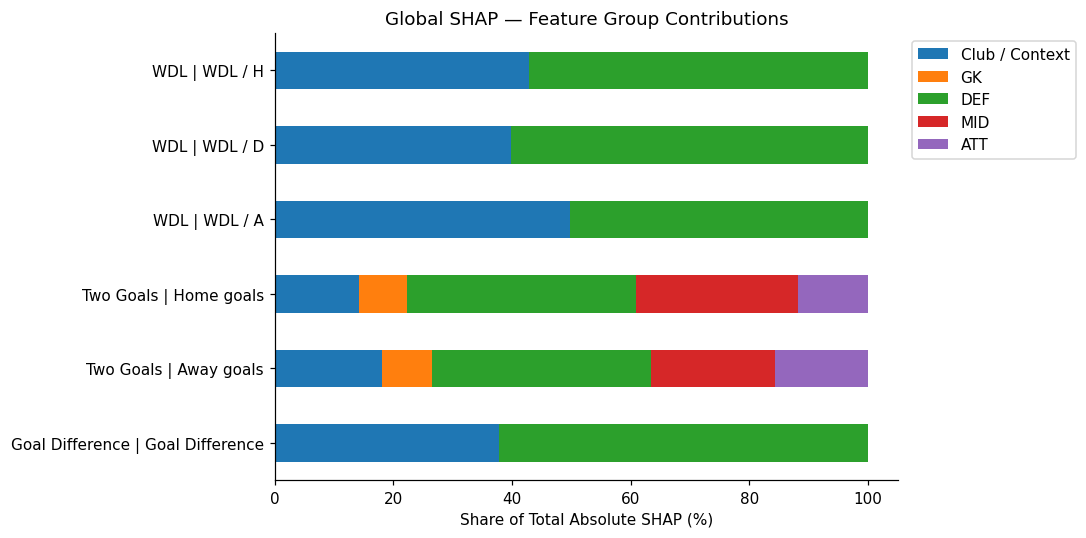

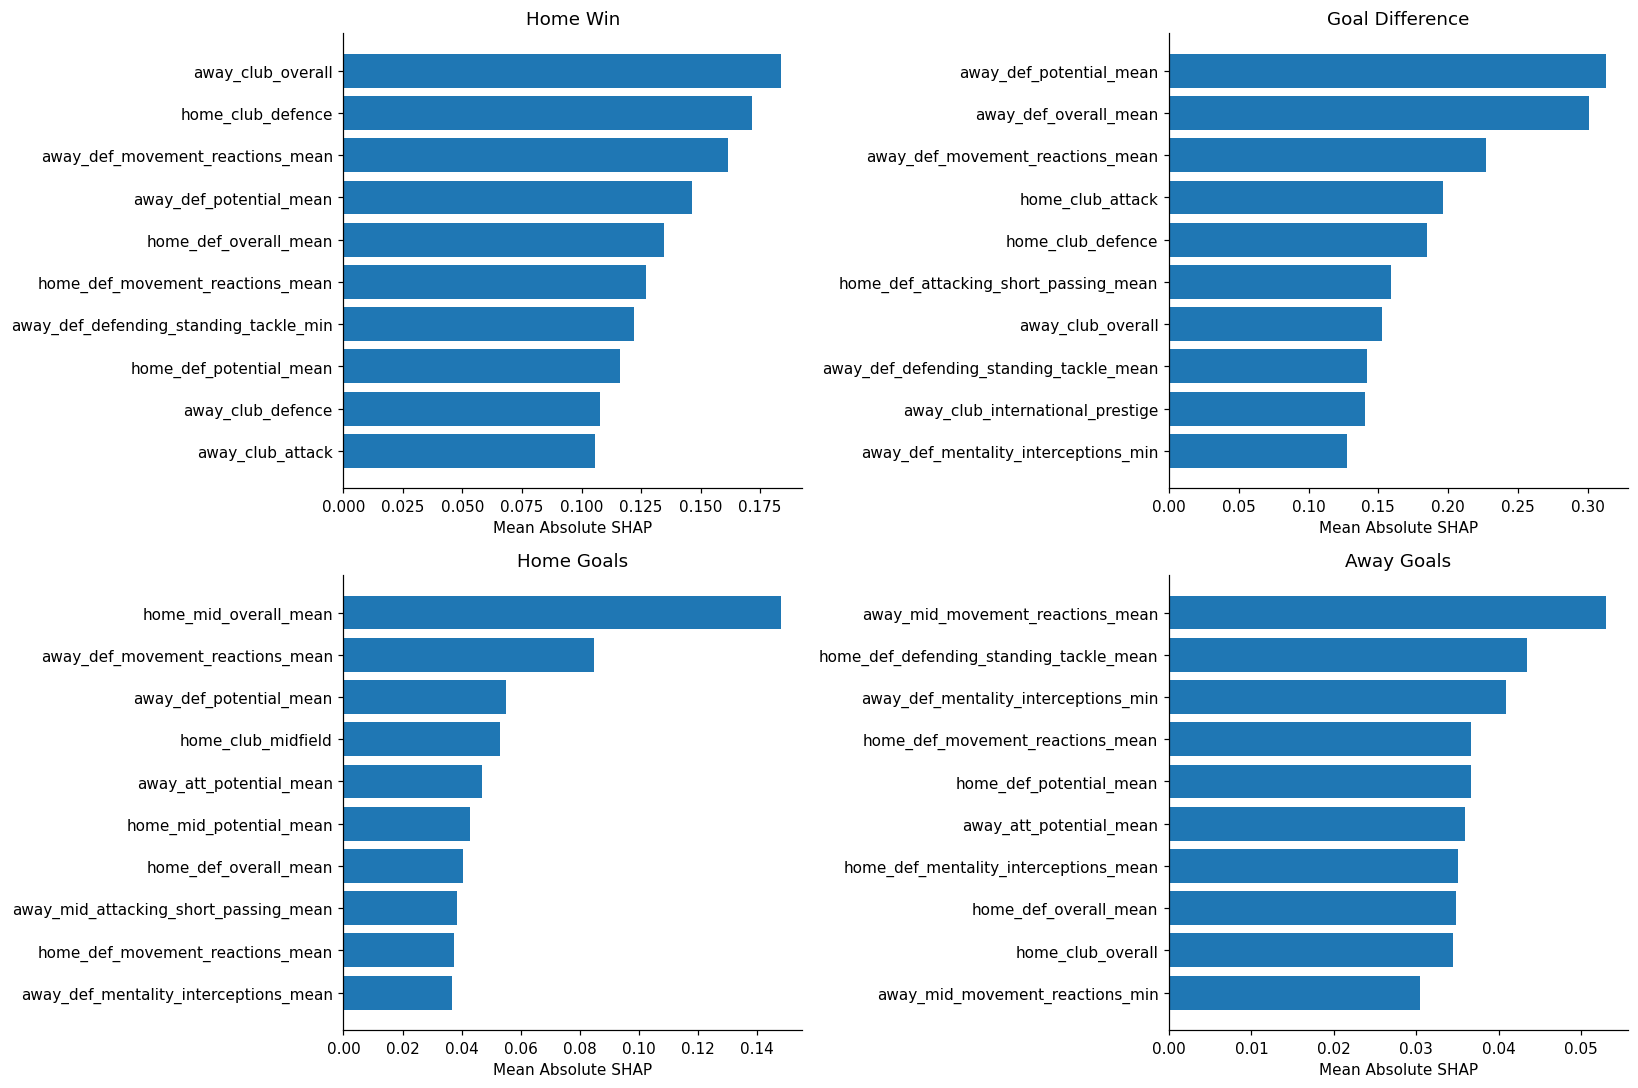

In [45]:
from pathlib import Path

shap_dir = Path('model/results/final_player_shap/global_shap')

global_imp = pd.read_csv(shap_dir / 'global_shap_all_features.csv')
group_imp = pd.read_csv(shap_dir / 'global_shap_position_groups.csv')

outputs = [
    ('WDL', 'WDL / H', 'Home Win'),
    ('Goal Difference', 'Goal Difference', 'Goal Difference'),
    ('Two Goals', 'Home goals', 'Home Goals'),
    ('Two Goals', 'Away goals', 'Away Goals')
]

# Figure 1: Position-group contribution shares
group_plot = group_imp.copy()
group_plot['output_name'] = group_plot.apply(
    lambda r: f"{r['route']} | {r['output']}", axis=1
)

group_table = group_plot.pivot_table(
    index='output_name', columns='group',
    values='mean_abs_shap', fill_value=0
)

group_table = group_table.div(group_table.sum(axis=1), axis=0) * 100
group_table = group_table.reindex(
    columns=['Club / Context', 'GK', 'DEF', 'MID', 'ATT'],
    fill_value=0
)

ax = group_table.plot(kind='barh', stacked=True, figsize=(10, 5))
ax.set_xlabel('Share of Total Absolute SHAP (%)')
ax.set_ylabel('')
ax.set_title('Global SHAP — Feature Group Contributions')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()


# Figure 2: Top features for four outputs
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (route, output, title) in zip(axes.flat, outputs):
    top = global_imp[
        (global_imp['route'] == route) &
        (global_imp['output'] == output)
    ].nlargest(10, 'mean_abs_shap').sort_values('mean_abs_shap')

    ax.barh(top['feature'], top['mean_abs_shap'])
    ax.set_title(title)
    ax.set_xlabel('Mean Absolute SHAP')

plt.tight_layout()
plt.show()

## Local SHAP for candidate matches

In [46]:
def find_cases(data):
    selected = []
    for title, season, date, home, away in CASE_REQUESTS:
        rows = data.loc[
            data.season.eq(season) & data.match_date.astype(str).str.startswith(date) &
            data.home_team.str.contains(home, case=False, regex=False, na=False) &
            data.away_team.str.contains(away, case=False, regex=False, na=False)
        ]
        if len(rows) == 1:
            row = rows.iloc[0]
            selected.append((title, row.name))
        else:
            print(f'Case unavailable or ambiguous ({len(rows)} rows): {title}')
    return selected


def local_shap(data, groups, saved, out):
    out.mkdir(parents=True, exist_ok=True)
    cases = find_cases(data)
    rows = []
    for title, index in cases:
        case = data.loc[index]

        for route, bundle in saved.items():
            X_all = numeric_input(bundle, groups[bundle['feature_set']])
            X = X_all.loc[[index]]
            bg = X_all.loc[data.season != '2025-26'].sample(n=min(100, (data.season != '2025-26').sum()), random_state=42)
            probs, raw = predict_bundle(bundle, X)
            label = decision_labels(route, probs, raw, bundle.get('threshold'))[0]
            rows.append({'case': title, 'match_id': case.match_id, 'season': case.season,
                         'data_split': 'test' if case.season == '2025-26' else 'train+valid',
                         'route': route, 'actual': case.label_90min_wdl,
                         'predicted': label, 'prob_A': probs[0, 0], 'prob_D': probs[0, 1], 'prob_H': probs[0, 2]})
            names = ['Home goals', 'Away goals'] if route == 'Two Goals' else ['WDL' if route == 'WDL' else 'Goal Difference']
            models = [bundle['models']['home'], bundle['models']['away']] if route == 'Two Goals' else [bundle['models']['main']]

            for name, model in zip(names, models):
                try:
                    sv = shap_for_pipeline(model, X, bg)
                    if sv.values.ndim == 3:
                        # Explain the predicted WDL class in the model-margin (logit) space.
                        class_index = int(np.argmax(probs[0]))
                        explanation = sv[0, :, class_index]
                        suffix = ORDER[class_index]
                    else:
                        explanation = sv[0]
                        suffix = name
                    plt.figure(figsize=(9, 5))
                    shap.plots.waterfall(explanation, max_display=15, show=False)
                    plt.title(f'{title}\n{route} | {suffix}')
                    safe = ''.join(ch if ch.isalnum() else '_' for ch in title + '_' + route + '_' + suffix)
                    plt.tight_layout()
                    plt.savefig(out / f'{safe}.png', dpi=180, bbox_inches='tight')
                    plt.close()
                except Exception as e:
                    print(f'Local SHAP failed: {title} / {route}: {e}')

    cases_df = pd.DataFrame(rows)
    cases_df.to_csv(out / 'case_predictions.csv', index=False)
    return cases_df

In [47]:
local_shap(data, groups, saved, OUTPUT / 'local_shap')
cases_file = OUTPUT / 'local_shap' / 'case_predictions.csv'
display(pd.read_csv(cases_file))

,case,match_id,season,data_split,route,actual,predicted,prob_A,prob_D,prob_H
0,Real Madrid vs Arsenal,UCL_f3203ae5c0598bac,2024-25,train+valid,Goal Difference,A,H,0.196622,0.186804,0.616574
1,Real Madrid vs Arsenal,UCL_f3203ae5c0598bac,2024-25,train+valid,Two Goals,A,H,0.221738,0.207737,0.570526
2,Real Madrid vs Arsenal,UCL_f3203ae5c0598bac,2024-25,train+valid,WDL,A,H,0.186699,0.143228,0.670073
3,Aston Villa vs PSG,UCL_98f6d7cf8e586b3b,2024-25,train+valid,Goal Difference,H,A,0.414121,0.219063,0.366816
4,Aston Villa vs PSG,UCL_98f6d7cf8e586b3b,2024-25,train+valid,Two Goals,H,A,0.426994,0.250479,0.322526
5,Aston Villa vs PSG,UCL_98f6d7cf8e586b3b,2024-25,train+valid,WDL,H,A,0.427344,0.253592,0.319064
6,Inter vs Bodo/Glimt,UCL_2b764a5a3334e850,2025-26,test,Goal Difference,A,H,0.037597,0.073253,0.889150
7,Inter vs Bodo/Glimt,UCL_2b764a5a3334e850,2025-26,test,Two Goals,A,H,0.029870,0.085796,0.884334
8,Inter vs Bodo/Glimt,UCL_2b764a5a3334e850,2025-26,test,WDL,A,H,0.036112,0.109083,0.854805
9,Bayern vs Real Madrid,UCL_42a3140f825c951c,2025-26,test,Goal Difference,H,H,0.322153,0.215915,0.461932


In [48]:
# Local SHAP: Match explanation

def explain_match(match_date, home_keyword, away_keyword):
    mask = (
        data['match_date'].astype(str).str.startswith(match_date) &
        data['home_team'].str.contains(home_keyword, case=False, regex=False, na=False) &
        data['away_team'].str.contains(away_keyword, case=False, regex=False, na=False)
    )

    matches = data.loc[mask]
    if len(matches) != 1:
        raise ValueError(f'Expected one match, found {len(matches)}')

    idx = matches.index[0]
    match = matches.iloc[0]

    print(f"\n{match['home_team']} vs {match['away_team']}")
    print(f"Date: {match['match_date']}")
    print(f"Actual 90-minute score: {int(match['label_90min_home_goals'])}-{int(match['label_90min_away_goals'])}")
    print(f"Actual WDL: {match['label_90min_wdl']}")

    prediction_rows = []
    explanations = []

    for route in ['WDL', 'Goal Difference', 'Two Goals']:
        bundle = saved[route]
        features = numeric_input(bundle, groups[bundle['feature_set']])
        X = features.loc[[idx]]

        probs, raw = predict_bundle(bundle, X)
        predicted = decision_labels(route, probs, raw, bundle.get('threshold'))[0]

        record = {
            'route': route,
            'predicted': predicted,
            'P(A)': probs[0, 0],
            'P(D)': probs[0, 1],
            'P(H)': probs[0, 2]
        }

        if route == 'Goal Difference':
            record['pred_goal_diff'] = float(raw[0])

        if route == 'Two Goals':
            record['pred_home_goals'] = float(raw[0][0])
            record['pred_away_goals'] = float(raw[1][0])

        prediction_rows.append(record)

        train_mask = data['season'] != '2025-26'
        background = features.loc[train_mask].sample(
            n=min(100, train_mask.sum()), random_state=42
        )

        models = bundle['models']
        targets = (
            [('Home Goals', models['home']), ('Away Goals', models['away'])]
            if route == 'Two Goals'
            else [('WDL' if route == 'WDL' else 'Goal Difference', models['main'])]
        )

        for target, model in targets:
            sv = shap_for_pipeline(model, X, background)

            if route == 'WDL':
                class_index = ORDER.index(predicted)
                explanation = sv[0, :, class_index]
                title = f'WDL — {predicted}'
            else:
                explanation = sv[0]
                title = f'{route} — {target}'

            explanations.append((title, explanation))

    display(pd.DataFrame(prediction_rows).round(4))

    for title, explanation in explanations:
        print(f'\n{title}')

        plt.figure(figsize=(10, 5))
        shap.plots.waterfall(explanation, max_display=12, show=False)
        plt.title(title)
        plt.tight_layout()
        plt.show()
        plt.close()

        contributions = pd.DataFrame({
            'feature': explanation.feature_names,
            'value': explanation.values
        })

        print('Top positive contributions:')
        display(contributions.nlargest(5, 'value').round(4))

        print('Top negative contributions:')
        display(contributions.nsmallest(5, 'value').round(4))

### Case 1: Correct prediction: Bayern vs Real Madrid

All three models correctly predicted Bayern Munich's victory, with SHAP highlighting Bayern's attacking strength, midfield quality, and defensive attributes, while Real Madrid's offensive and defensive capabilities provided substantial counterbalancing contributions.

These findings are broadly consistent with the actual match. Bayern's midfield participation and attacking quality helped generate scoring opportunities, while Real Madrid demonstrated significant offensive strength through goals from Arda Güler and Kylian Mbappé.

However, the match was ultimately decided by late events, particularly Camavinga's dismissal and Bayern's subsequent goals. These unpredictable events, together with individual mistakes and exceptional finishing, explain why the models correctly predicted the winner but substantially underestimated the total goals.

**Key takeaway:** Player attributes helped capture the underlying competitive balance, while match-specific events determined the final scoreline.


FC Bayern München vs Real Madrid CF
Date: 2026-04-15
Actual 90-minute score: 4-3
Actual WDL: H


,route,predicted,P(A),P(D),P(H),pred_goal_diff,pred_home_goals,pred_away_goals
0,WDL,H,0.3535,0.1912,0.4552,NaN,NaN,NaN
1,Goal Difference,H,0.3222,0.2159,0.4619,0.3285,NaN,NaN
2,Two Goals,H,0.3398,0.2244,0.4358,NaN,1.823,1.5912



WDL — H


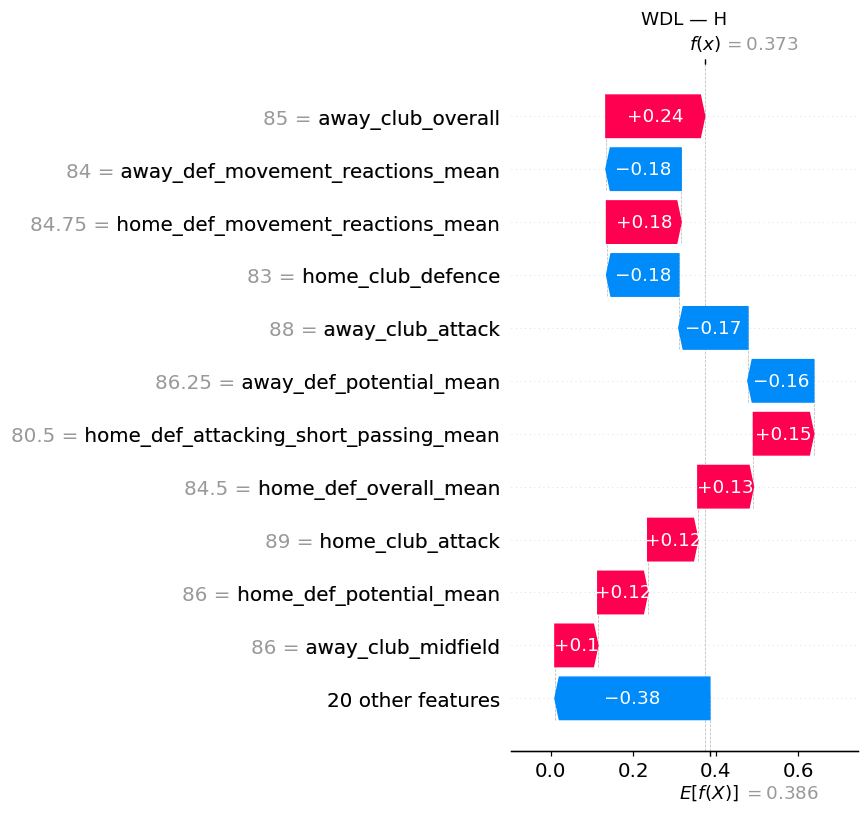

Top positive contributions:


,feature,value
6,away_club_overall,0.2394
17,home_def_movement_reactions_mean,0.1806
22,home_def_attacking_short_passing_mean,0.1461
15,home_def_overall_mean,0.1347
1,home_club_attack,0.1214


Top negative contributions:


,feature,value
25,away_def_movement_reactions_mean,-0.1822
3,home_club_defence,-0.1751
7,away_club_attack,-0.1673
24,away_def_potential_mean,-0.1597
9,away_club_defence,-0.1012



Goal Difference — Goal Difference


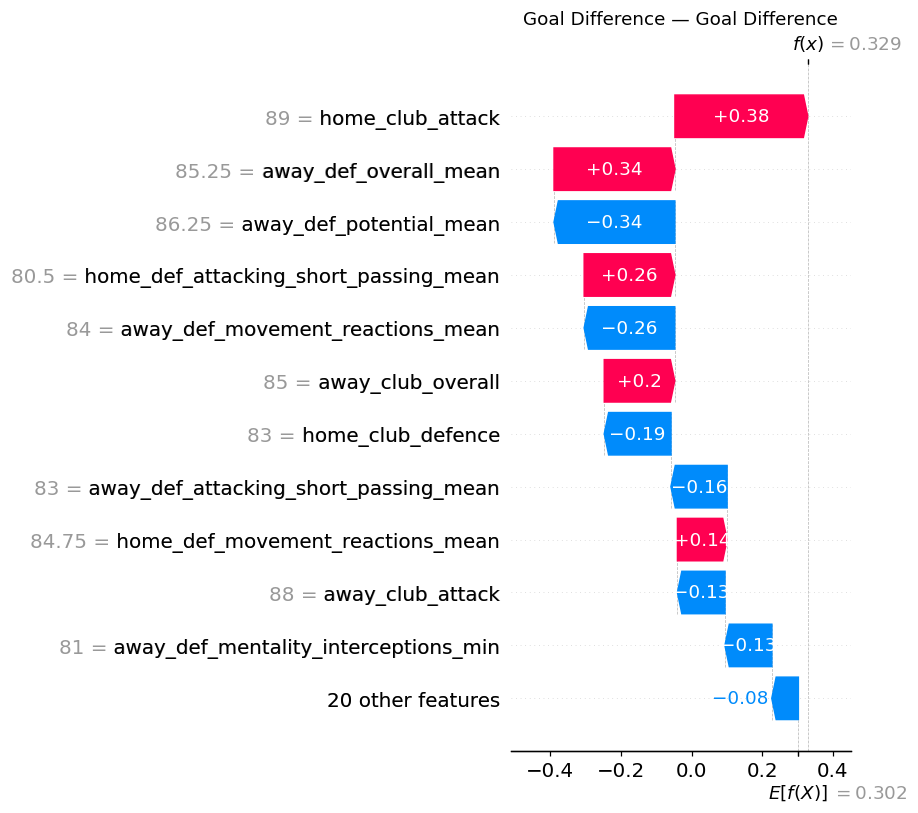

Top positive contributions:


,feature,value
1,home_club_attack,0.3755
23,away_def_overall_mean,0.3420
22,home_def_attacking_short_passing_mean,0.2563
6,away_club_overall,0.1992
17,home_def_movement_reactions_mean,0.1403


Top negative contributions:


,feature,value
24,away_def_potential_mean,-0.3415
25,away_def_movement_reactions_mean,-0.2561
3,home_club_defence,-0.1886
30,away_def_attacking_short_passing_mean,-0.1587
7,away_club_attack,-0.1343



Two Goals — Home Goals


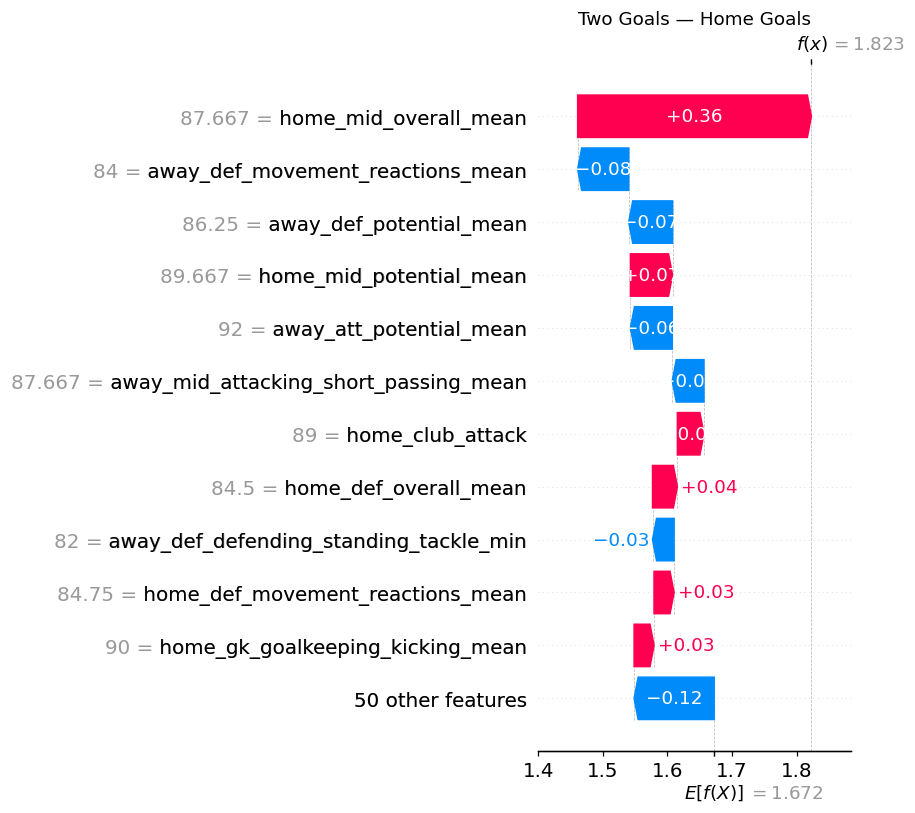

Top positive contributions:


,feature,value
27,home_mid_overall_mean,0.3619
28,home_mid_potential_mean,0.0652
1,home_club_attack,0.0412
19,home_def_overall_mean,0.0385
21,home_def_movement_reactions_mean,0.0310


Top negative contributions:


,feature,value
44,away_def_movement_reactions_mean,-0.0790
43,away_def_potential_mean,-0.0679
56,away_att_potential_mean,-0.0648
54,away_mid_attacking_short_passing_mean,-0.0491
48,away_def_defending_standing_tackle_min,-0.0334



Two Goals — Away Goals


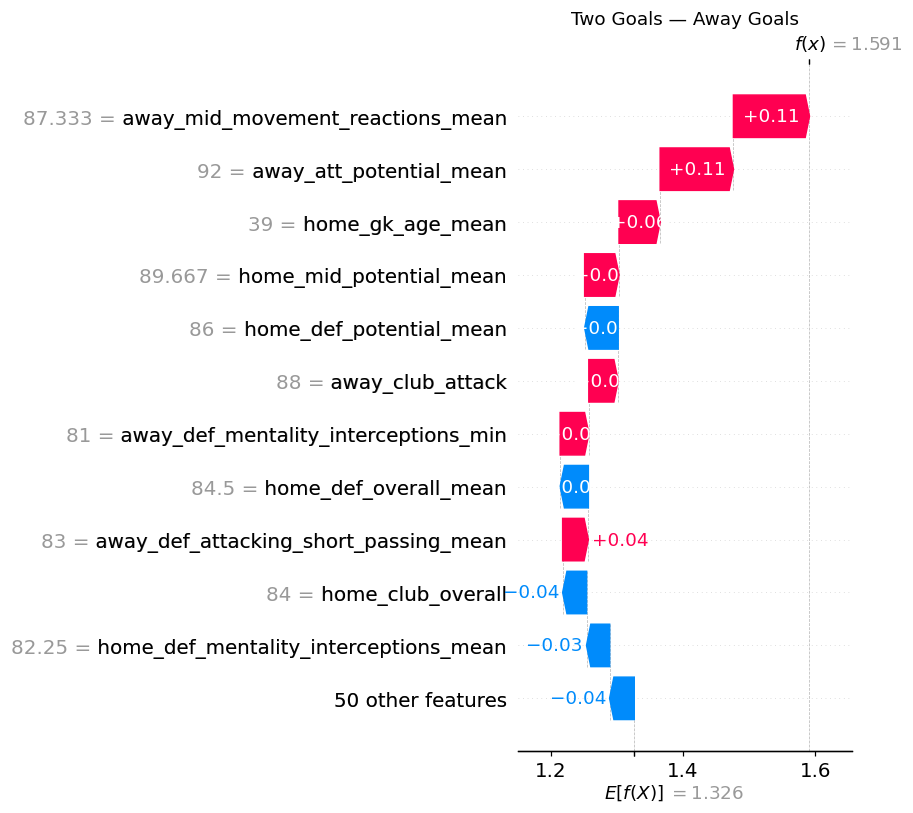

Top positive contributions:


,feature,value
52,away_mid_movement_reactions_mean,0.1150
56,away_att_potential_mean,0.1108
18,home_gk_age_mean,0.0622
28,home_mid_potential_mean,0.0520
7,away_club_attack,0.0443


Top negative contributions:


,feature,value
20,home_def_potential_mean,-0.0506
19,home_def_overall_mean,-0.0425
0,home_club_overall,-0.0361
22,home_def_mentality_interceptions_mean,-0.0349
16,home_gk_goalkeeping_kicking_mean,-0.0306


In [49]:
explain_match(
    match_date='2026-04-15',
    home_keyword='Bayern',
    away_keyword='Real Madrid'
)

### Case 2 90-minute draw, PSG eventually won on penalties

The models produced conflicting predictions for the 2026 Champions League final. The WDL and Goal Difference models favored Arsenal, partly because of an unusually large neutral-venue effect, whereas the Two Goals model favored PSG, supported by its midfield quality.

The Two Goals explanation is consistent with UEFA's tactical observations. PSG's midfield, particularly Vitinha, controlled possession and supported repeated attacking movements. However, Arsenal's compact defensive organization restricted PSG's open-play chances, preventing their territorial dominance from translating into a regulation-time victory.

PSG eventually equalized through a penalty and won the subsequent shootout. The models did not account for tactical adjustments, early match developments, penalty incidents, or shootout execution.

**Key takeaway:** Position-specific player features captured meaningful aspects of PSG's technical superiority, but static pre-match attributes could not fully represent Arsenal's defensive strategy or the dynamic events that produced a draw and eventual penalty-shootout victory.


Paris Saint-Germain FC vs Arsenal FC
Date: 2026-05-30
Actual 90-minute score: 1-1
Actual WDL: D


,route,predicted,P(A),P(D),P(H),pred_goal_diff,pred_home_goals,pred_away_goals
0,WDL,A,0.6829,0.0453,0.2718,NaN,NaN,NaN
1,Goal Difference,A,0.5688,0.1987,0.2325,-0.811,NaN,NaN
2,Two Goals,H,0.2674,0.2313,0.5013,NaN,1.7974,1.2554



WDL — A


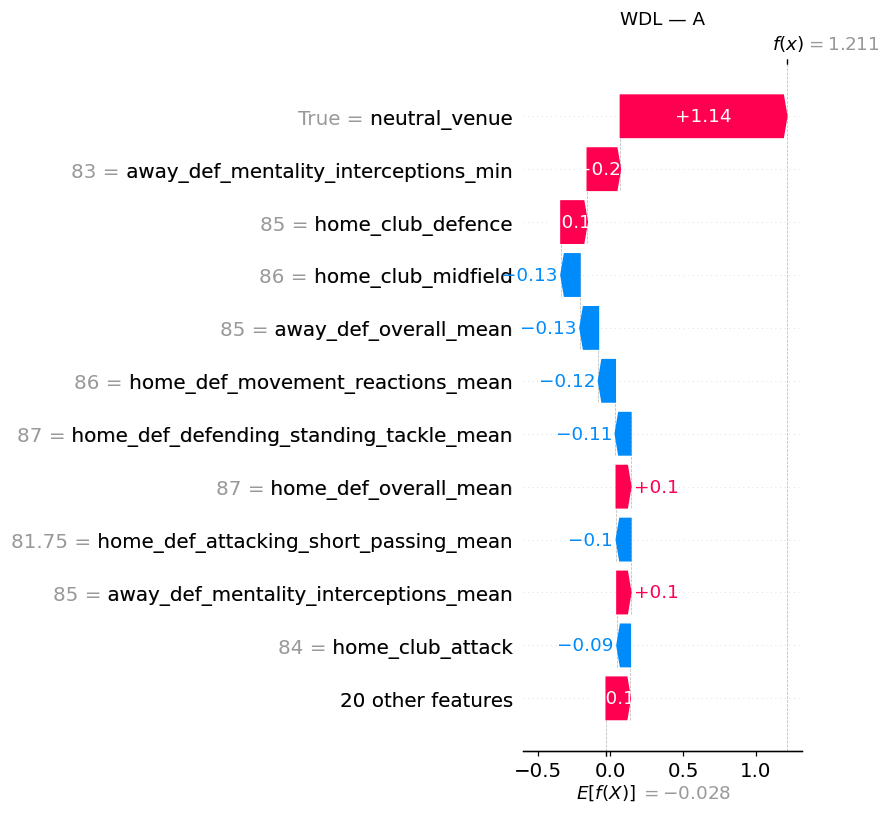

Top positive contributions:


,feature,value
12,neutral_venue,1.1424
27,away_def_mentality_interceptions_min,0.2274
3,home_club_defence,0.1808
15,home_def_overall_mean,0.1001
26,away_def_mentality_interceptions_mean,0.0956


Top negative contributions:


,feature,value
2,home_club_midfield,-0.1305
23,away_def_overall_mean,-0.1269
17,home_def_movement_reactions_mean,-0.1153
20,home_def_defending_standing_tackle_mean,-0.1072
22,home_def_attacking_short_passing_mean,-0.1001



Goal Difference — Goal Difference


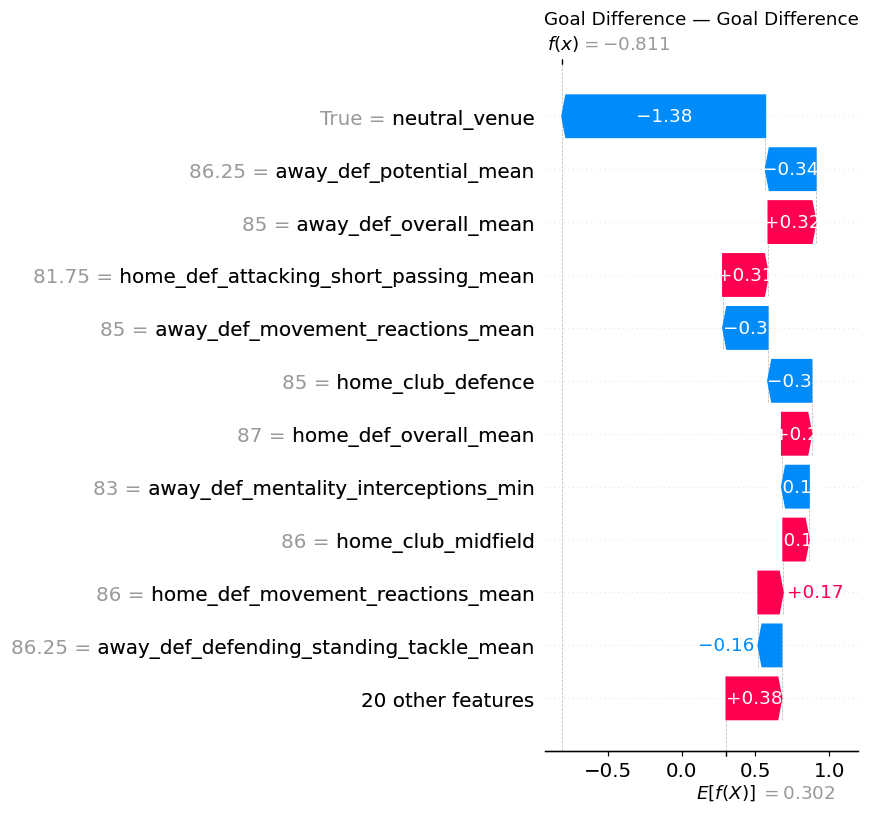

Top positive contributions:


,feature,value
23,away_def_overall_mean,0.3223
22,home_def_attacking_short_passing_mean,0.3078
15,home_def_overall_mean,0.2029
2,home_club_midfield,0.1760
17,home_def_movement_reactions_mean,0.1688


Top negative contributions:


,feature,value
12,neutral_venue,-1.3784
24,away_def_potential_mean,-0.3415
25,away_def_movement_reactions_mean,-0.3049
3,home_club_defence,-0.2967
27,away_def_mentality_interceptions_min,-0.1854



Two Goals — Home Goals


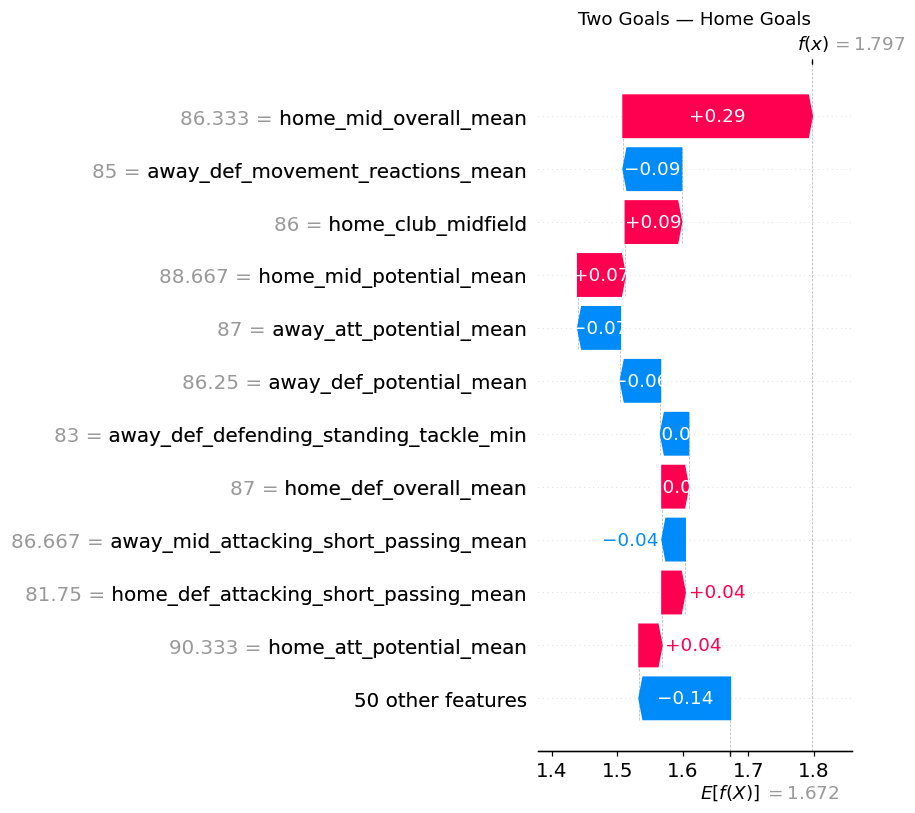

Top positive contributions:


,feature,value
27,home_mid_overall_mean,0.2888
2,home_club_midfield,0.0859
28,home_mid_potential_mean,0.0727
19,home_def_overall_mean,0.0406
26,home_def_attacking_short_passing_mean,0.0355


Top negative contributions:


,feature,value
44,away_def_movement_reactions_mean,-0.0894
56,away_att_potential_mean,-0.0652
43,away_def_potential_mean,-0.0612
48,away_def_defending_standing_tackle_min,-0.0428
54,away_mid_attacking_short_passing_mean,-0.0355



Two Goals — Away Goals


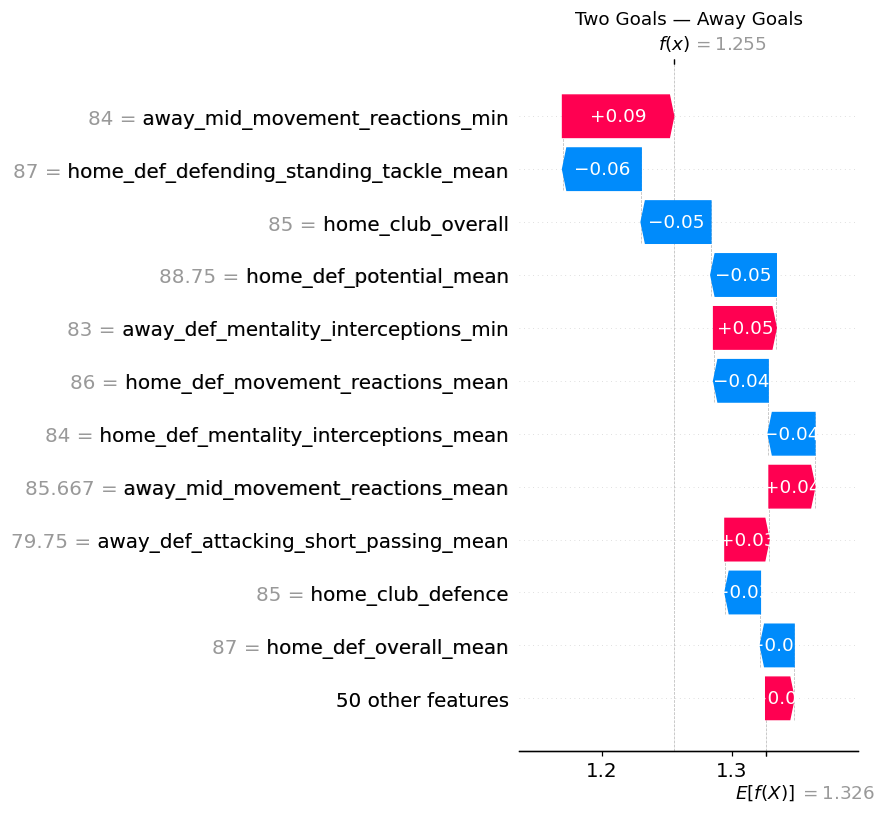

Top positive contributions:


,feature,value
53,away_mid_movement_reactions_min,0.0853
46,away_def_mentality_interceptions_min,0.0481
52,away_mid_movement_reactions_mean,0.0352
49,away_def_attacking_short_passing_mean,0.0339
7,away_club_attack,0.0247


Top negative contributions:


,feature,value
24,home_def_defending_standing_tackle_mean,-0.0603
0,home_club_overall,-0.0535
20,home_def_potential_mean,-0.0502
21,home_def_movement_reactions_mean,-0.0418
22,home_def_mentality_interceptions_mean,-0.0359


In [50]:
explain_match(
    match_date='2026-05-30',
    home_keyword='Paris Saint-Germain',
    away_keyword='Arsenal'
)

# Part XI Baselines, Voting and Time-Aware Stacking

- Baselines: Always Home Win; Overall Difference Logistic
- Single routes: WDL, Goal Difference, Two Goals
- Ensembles: Hard Vote; Soft Vote; Probability Stacking; Stacking + Club Context
- Metrics: Accuracy, Macro-AUC, Macro-F1, Log Loss, multiclass Brier Score

In [51]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ENSEMBLE_DIR = Path('model/results/ensemble')
ENSEMBLE_DIR.mkdir(parents=True, exist_ok=True)

ROUTES = ['WDL', 'Goal Difference', 'Two Goals']
ROUTE_KEY = {'WDL': 'wdl', 'Goal Difference': 'gd', 'Two Goals': 'goals'}
CLASSES = ['A', 'D', 'H']
FOLD_YEARS = [2021, 2022, 2023, 2024]

# Reuse selected, trained routes and features from Part VIII.
if 'saved' not in globals():
    model_dir = Path('model/results/final_player_shap')
    saved = {route: joblib.load(model_dir / f'model_{route.lower().replace(" ", "_")}.joblib')
             for route in ROUTES}

if 'data' not in globals():
    data = pd.read_csv('data/match_dataset/matches_full.csv', low_memory=False).reset_index(drop=True)

if 'groups' not in globals():
    groups = feature_groups(data)

season_year = data['season'].astype(str).str[:4].astype(int)
print('Selected route settings:')
for route in ROUTES:
    bundle = saved[route]
    print(f"{route:16s}  {bundle['algo']:14s}  {bundle['feature_set']}  threshold={bundle.get('threshold')}")

Selected route settings:
WDL               Logistic        club_def  threshold=nan
Goal Difference   Ridge           club_def  threshold=0.1
Two Goals         RandomForest    club_position_core  threshold=0.3999999999999998


In [52]:
# Generate chronological out-of-fold predictions
def get_prior_predictions(year):
    train_mask = season_year < year
    valid_mask = season_year == year

    valid = data.loc[valid_mask].copy()
    output = pd.DataFrame(index=valid.index)
    output['season_year'] = year
    output['actual'] = valid['label_90min_wdl'].values

    for name in ['overall', 'attack', 'defence']:
        output[f'{name}_gap'] = valid[f'home_club_{name}'] - valid[f'away_club_{name}']
    output['neutral_venue'] = valid['neutral_venue'].astype(float)

    # A football-only baseline: one feature (difference in club overall).
    gap_train = (data.loc[train_mask, 'home_club_overall'] -
                 data.loc[train_mask, 'away_club_overall']).to_frame('gap')
    gap_valid = output[['overall_gap']].rename(columns={'overall_gap': 'gap'})

    baseline = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                             LogisticRegression(C=1.0, max_iter=2000, random_state=42))
    baseline.fit(gap_train, data.loc[train_mask, 'label_90min_wdl'])
    output[[f'overall_p_{cls}' for cls in CLASSES]] = baseline.predict_proba(gap_valid)

    # Three final model routes, refitted only on earlier seasons.
    for route in ROUTES:
        setting = saved[route]
        features = groups[setting['feature_set']]
        Xtrain, Xvalid, _ = clean_frames(features.loc[train_mask], features.loc[valid_mask])

        fitted = fit_bundle(route, setting['algo'], Xtrain, data.loc[train_mask], quick=False)
        probabilities, raw = predict_bundle(fitted, Xvalid)

        prefix = ROUTE_KEY[route]
        output[[f'{prefix}_p_{cls}' for cls in CLASSES]] = probabilities

        threshold = setting.get('threshold')
        if pd.isna(threshold):
            threshold = None
        output[f'{prefix}_pred'] = decision_labels(route, probabilities, raw, threshold)

    return output


oof = pd.concat([get_prior_predictions(year) for year in FOLD_YEARS]).sort_index()
oof.to_csv(ENSEMBLE_DIR / 'base_oof_probabilities.csv', index_label='match_index')

print('OOF matches:', len(oof))
display(oof.groupby('season_year')['actual'].agg(['count', 'nunique']))

OOF matches: 524


,count,nunique
season_year,,
2021,113,3
2022,119,3
2023,119,3
2024,173,3


### Voting and stacking

- **Hard Vote:** majority of the three routes' class decisions; ties are resolved by the average probabilities.
- **Soft Vote:** average the three probability distributions.
- **Probability Stacking:** fit Logistic Regression on the 9 probabilities.
- **Stacking + Context:** the same meta model plus four pre-match features (`overall_gap`, `attack_gap`, `defence_gap`, `neutral_venue`).

The last two are both stacking approaches; the second is a richer **meta model** rather than a fundamentally different learning paradigm.

In [53]:
PROB_COLUMNS = [f'{ROUTE_KEY[route]}_p_{cls}' for route in ROUTES for cls in CLASSES]
CONTEXT_COLUMNS = ['overall_gap', 'attack_gap', 'defence_gap', 'neutral_venue']

def ensemble_probabilities(frame):
    per_route = [frame[[f'{ROUTE_KEY[r]}_p_{c}' for c in CLASSES]].to_numpy() for r in ROUTES]
    return np.mean(per_route, axis=0)

def hard_vote(frame):
    votes = frame[[f'{ROUTE_KEY[r]}_pred' for r in ROUTES]].to_numpy()
    counts = np.stack([(votes == c).sum(axis=1) for c in CLASSES], axis=1)
    soft = ensemble_probabilities(frame)

    # Probabilities based on vote frequencies; tie resolution uses soft voting.
    vote_probs = counts / len(ROUTES)
    tie_break = np.where(counts == counts.max(axis=1, keepdims=True), soft, -1)
    predicted = np.array(CLASSES)[tie_break.argmax(axis=1)]
    return vote_probs, predicted

def fit_meta(history, columns):
    model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                          LogisticRegression(C=0.3, max_iter=2500, random_state=42))
    model.fit(history[columns], history['actual'])
    return model

def meta_probabilities(model, frame, columns):
    values = model.predict_proba(frame[columns])
    return values[:, [list(model[-1].classes_).index(c) for c in CLASSES]]

def evaluate_ensemble(actual, prob, predicted=None):
    prob = np.asarray(prob, dtype=float)
    prob = np.clip(prob, 1e-9, 1)
    prob = prob / prob.sum(axis=1, keepdims=True)

    if predicted is None:
        predicted = np.array(CLASSES)[prob.argmax(axis=1)]

    result = evaluate(actual, prob, predicted)
    indicator = (np.asarray(actual)[:, None] == np.array(CLASSES)[None, :]).astype(float)
    result['brier'] = np.mean(np.sum((prob - indicator) ** 2, axis=1))
    return result

In [54]:
records = []

for year in FOLD_YEARS[1:]:
    history = oof.loc[oof.season_year < year]
    current = oof.loc[oof.season_year == year]
    actual = current['actual'].to_numpy()

    candidate_outputs = {
        'Always Home Win': (np.tile([0.0, 0.0, 1.0], (len(current), 1)),
                            np.repeat('H', len(current))),
        'Overall Diff Logistic': (current[[f'overall_p_{c}' for c in CLASSES]].to_numpy(), None),
        'WDL': (current[[f'wdl_p_{c}' for c in CLASSES]].to_numpy(), current['wdl_pred'].to_numpy()),
        'Goal Difference': (current[[f'gd_p_{c}' for c in CLASSES]].to_numpy(), current['gd_pred'].to_numpy()),
        'Two Goals': (current[[f'goals_p_{c}' for c in CLASSES]].to_numpy(), current['goals_pred'].to_numpy()),
        'Hard Vote': hard_vote(current),
        'Soft Vote': (ensemble_probabilities(current), None),
    }

    for name, columns in [('Probability Stacking', PROB_COLUMNS),
                          ('Stacking + Context', PROB_COLUMNS + CONTEXT_COLUMNS)]:
        model = fit_meta(history, columns)
        candidate_outputs[name] = (meta_probabilities(model, current, columns), None)

    for name, (prob, pred) in candidate_outputs.items():
        metrics = evaluate_ensemble(actual, prob, pred)
        records.append({'season': f'{year}-{str(year + 1)[-2:]}', 'method': name,
                        'n_matches': len(current), **metrics})

comparison = pd.DataFrame(records)
comparison.to_csv(ENSEMBLE_DIR / 'ensemble_rolling_by_season.csv', index=False)

summary = comparison.groupby('method', as_index=False)[
    ['accuracy', 'macro_auc', 'macro_f1', 'brier', 'log_loss']].mean()
summary['acc_rank'] = summary['accuracy'].rank(ascending=False)
summary['auc_rank'] = summary['macro_auc'].rank(ascending=False)
summary['avg_rank'] = (summary['acc_rank'] + summary['auc_rank']) / 2
summary = summary.sort_values(['avg_rank', 'brier', 'log_loss'])
summary.to_csv(ENSEMBLE_DIR / 'ensemble_rolling_summary.csv', index=False)

display(summary.round(4))
display(comparison.pivot(index='season', columns='method', values='accuracy').round(4))

,method,accuracy,macro_auc,macro_f1,brier,log_loss,acc_rank,auc_rank,avg_rank
7,Two Goals,0.5638,0.6858,0.4118,0.5539,0.9388,2.0,2.0,2.0
5,Soft Vote,0.5622,0.6887,0.4099,0.5532,0.9366,4.0,1.0,2.5
1,Goal Difference,0.5642,0.6789,0.4635,0.5574,0.9430,1.0,4.0,2.5
8,WDL,0.5622,0.6768,0.4121,0.5601,0.9482,4.0,5.0,4.5
6,Stacking + Context,0.5498,0.6806,0.4074,0.5629,0.9466,8.0,3.0,5.5
2,Hard Vote,0.5622,0.6285,0.4111,0.7984,7.8972,4.0,8.0,6.0
3,Overall Diff Logistic,0.5509,0.6745,0.3965,0.5542,0.9378,7.0,6.0,6.5
4,Probability Stacking,0.5545,0.6658,0.4054,0.5626,0.9496,6.0,7.0,6.5
0,Always Home Win,0.4889,0.5000,0.2189,1.0222,10.5920,9.0,9.0,9.0


method,Always Home Win,Goal Difference,Hard Vote,Overall Diff Logistic,Probability Stacking,Soft Vote,Stacking + Context,Two Goals,WDL
season,,,,,,,,,
2022-23,0.4790,0.5546,0.5462,0.5546,0.5630,0.5546,0.5546,0.5882,0.5462
2023-24,0.4790,0.5714,0.5798,0.5546,0.5630,0.5714,0.5630,0.5714,0.5798
2024-25,0.5087,0.5665,0.5607,0.5434,0.5376,0.5607,0.5318,0.5318,0.5607


# Part XII Final Test Evaluation

In [55]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from IPython.display import display

FINAL_DIR = Path('model/results/ensemble_final')
FINAL_DIR.mkdir(parents=True, exist_ok=True)

train_mask = season_year <= 2024
test_mask = season_year == 2025

train_data = data.loc[train_mask]
test_data = data.loc[test_mask]

y_test = test_data['label_90min_wdl'].to_numpy()

print('Train + Valid:', len(train_data))
print('Test:', len(test_data))

# Refit the three previously selected base models
final_models = {}
test_probabilities = {}
test_decisions = {}

for route in ROUTES:
    setting = saved[route]
    features = groups[setting['feature_set']]

    Xtrain, Xtest, columns = clean_frames(features.loc[train_mask], features.loc[test_mask])

    model = fit_bundle(route, setting['algo'], Xtrain, train_data, quick=False)

    threshold = setting.get('threshold')
    if threshold is not None and pd.isna(threshold):
        threshold = None

    model.update({
        'feature_set': setting['feature_set'],
        'columns': columns,
        'threshold': threshold
    })

    prob, raw = predict_bundle(model, Xtest)
    pred = decision_labels(route, prob, raw, threshold)

    final_models[route] = model
    test_probabilities[route] = prob
    test_decisions[route] = pred

    joblib.dump(model, FINAL_DIR / f"model_{route.lower().replace(' ', '_')}.joblib")

    print(f"{route}: {setting['algo']} / {setting['feature_set']}")

# Baseline: Overall Difference Logistic
overall_train = (train_data['home_club_overall'] - train_data['away_club_overall']).to_frame('overall_gap')

overall_test = (test_data['home_club_overall'] - test_data['away_club_overall']).to_frame('overall_gap')

overall_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=2000, random_state=42)
)

overall_model.fit(overall_train, train_data['label_90min_wdl'])

overall_prob = overall_model.predict_proba(overall_test)
overall_prob = overall_prob[:, [list(overall_model[-1].classes_).index(c) for c in CLASSES]]

joblib.dump(overall_model, FINAL_DIR / 'model_overall_diff.joblib')

Train + Valid: 1259
Test: 174
WDL: Logistic / club_def
Goal Difference: Ridge / club_def
Two Goals: RandomForest / club_position_core


['model\\results\\ensemble_final\\model_overall_diff.joblib']

In [56]:
# Final comparison: two baselines + rolling validation top3 methods

soft_prob = np.mean([test_probabilities[route] for route in ROUTES], axis=0)

methods = {
    'Always Home Win': (np.tile([0.0, 0.0, 1.0], (len(test_data), 1)), np.repeat('H', len(test_data))),
    'Overall Diff': (overall_prob, None),
    'Two Goals': (test_probabilities['Two Goals'], test_decisions['Two Goals']),
    'Soft Vote': (soft_prob, None),
    'Goal Difference': (test_probabilities['Goal Difference'], test_decisions['Goal Difference'])
}

results = []
predictions = test_data[['match_id', 'season', 'home_team', 'away_team', 'label_90min_wdl']].copy()

for name, (prob, pred) in methods.items():
    if pred is None:
        pred = np.array(CLASSES)[prob.argmax(axis=1)]

    metrics = evaluate_ensemble(y_test, prob, pred)

    results.append({
        'method': name,
        'accuracy': metrics['accuracy'],
        'macro_auc': metrics['macro_auc'],
        'macro_f1': metrics['macro_f1'],
        'brier': metrics['brier'],
        'log_loss': metrics['log_loss']
    })

    prefix = name.lower().replace(' ', '_')
    predictions[f'{prefix}_pred'] = pred

    for i, cls in enumerate(CLASSES):
        predictions[f'{prefix}_p_{cls}'] = prob[:, i]

final_results = pd.DataFrame(results)

final_results['acc_rank'] = final_results['accuracy'].rank(ascending=False)
final_results['auc_rank'] = final_results['macro_auc'].rank(ascending=False)
final_results['avg_rank'] = (final_results['acc_rank'] + final_results['auc_rank']) / 2

final_results = final_results.sort_values(['avg_rank', 'brier'])

display(final_results.round(4))

final_results.to_csv(FINAL_DIR / 'final_test_comparison.csv', index=False)
predictions.to_csv(FINAL_DIR / 'final_test_predictions.csv', index=False)

,method,accuracy,macro_auc,macro_f1,brier,log_loss,acc_rank,auc_rank,avg_rank
2,Two Goals,0.5747,0.6729,0.4101,0.5582,0.9516,2.0,2.0,2.0
3,Soft Vote,0.5632,0.6875,0.3997,0.5584,0.9552,3.0,1.0,2.0
1,Overall Diff,0.5805,0.6581,0.4116,0.5634,0.9665,1.0,4.0,2.5
4,Goal Difference,0.5575,0.6659,0.4440,0.5647,0.9631,4.0,3.0,3.5
0,Always Home Win,0.4943,0.5000,0.2205,1.0115,10.4807,5.0,5.0,5.0


## Part XIII Missing FC27 clubs: Elo + Golo Top 5 proxy robustness

Sabah and Slovan Bratislava lack usable FC27 attributes. Compare **K=5 vs K=24** donor profiles selected by Elo and Golo distance. Donor *club* ratings are observed; where donor position features are absent from the precomputed UCL feature bank, the auxiliary nearest-rating step **estimates**, rather than observes, them. This approximation is explicitly acknowledged.

The sensitivity analysis uses 300 Monte Carlo trials per method per setting and is **not** a predictive-accuracy validation. The resulting championship/qualification estimates were broadly similar, so we retain **K=5** for the final fixture snapshot. The full descriptive importance of this appendix is the feature-generation and numerical comparison cells; three redundant difference charts are omitted.

In [57]:
import importlib
# Compatible with the current standalone proxy module and the earlier local filename.
import proxy_club as proxy
import ucl_simulator as sim

importlib.invalidate_caches()
proxy = importlib.reload(proxy)

ELO_PATH = next((str(path) for path in [Path('clubelo_candidates.csv'), Path('clubelo_screenshot_candidates.csv'),] if path.exists()), 'clubelo_candidates.csv')
CLUBS_PATH = 'data/output_final/clubs_2015_2027.csv'
BANK_PATH = 'data/match_dataset/team_feature_bank.csv'
FIXTURES_PATH = 'data/match_dataset/fixtures_2026_27_full.csv'
OUT_DIR = 'model/results/proxy_top5_top24'

In [58]:
neighbors, proxy_profiles, differences = proxy.compare_proxies(
    ELO_PATH, CLUBS_PATH, BANK_PATH, OUT_DIR,
    estimate_missing=True
)

# 397 raw team attributes + 416 derived position attributes = 813 features.
print('Generated profile columns:', len(proxy_profiles.columns))
print('Generated position-stat columns:', sum(
    c.startswith(('gk_', 'def_', 'mid_', 'att_')) for c in proxy_profiles.columns
))
assert 'att_attacking_finishing_mean' in proxy_profiles.columns
assert 'def_mentality_interceptions_min' in proxy_profiles.columns

show_cols = ['team', 'k', 'n_features', 'n_estimated_donors',
             'club_overall', 'club_attack', 'club_midfield', 'club_defence']
display(proxy_profiles[show_cols].round(3))

for team in proxy.TARGETS:
    print(f'\n{team}: Top 5 donor profiles')
    display(neighbors.loc[(neighbors.target == team) & (neighbors.k == 5),
                         ['fifa_name', 'elo', 'golo', 'weight', 'feature_source']].reset_index(drop=True))

Generated profile columns: 819
Generated position-stat columns: 416


,team,k,n_features,n_estimated_donors,club_overall,club_attack,club_midfield,club_defence
0,Sabah,5,813,5,67.849,68.045,68.071,67.406
1,Sabah,24,813,24,67.497,67.912,67.581,67.174
2,Slovan Bratislava,5,813,5,66.796,66.640,66.738,65.310
3,Slovan Bratislava,24,813,24,67.021,67.513,66.916,66.525



Sabah: Top 5 donor profiles


,fifa_name,elo,golo,weight,feature_source
0,FC Metz,1561.0,1.53,0.258790,estimated_from_rating_neighbors
1,KV Mechelen,1560.0,1.53,0.249110,estimated_from_rating_neighbors
2,Cercle Brugge,1558.0,1.49,0.241537,estimated_from_rating_neighbors
3,Servette FC,1557.0,1.42,0.148248,estimated_from_rating_neighbors
4,Tromsø IL,1558.0,1.35,0.102315,estimated_from_rating_neighbors



Slovan Bratislava: Top 5 donor profiles


,fifa_name,elo,golo,weight,feature_source
0,Mantova,1539.0,1.45,0.289702,estimated_from_rating_neighbors
1,FC Basel,1536.0,1.57,0.231672,estimated_from_rating_neighbors
2,Rot-Weiß Essen,1544.0,1.62,0.171334,estimated_from_rating_neighbors
3,Hartberg,1542.0,1.37,0.153646,estimated_from_rating_neighbors
4,Lillestrøm SK,1542.0,1.37,0.153646,estimated_from_rating_neighbors


In [59]:
fixtures = pd.read_csv(FIXTURES_PATH)
print(sim.audit_fixtures(fixtures, as_of='2026-11-26'))

base_profiles = proxy.build_partial_fixture_profiles(fixtures)
required = sorted({c[5:] for bundle in final_models.values() for c in bundle['columns']
                   if c.startswith(('home_', 'away_'))} - {'team', 'club_id'})
print('Required team-level input fields:', len(required))

for k in [5, 24]:
    patched = proxy.patch_profiles(base_profiles, proxy_profiles, k)
    for team in proxy.TARGETS:
        missing = [c for c in required if pd.isna(patched[team].get(c))]
        print(f'{team}, Top {k}: {len(missing)} missing of {len(required)} model inputs')
        if missing:
            raise ValueError(f'{team}, Top {k}: missing actual model inputs: {missing}')

print('All four proxy profiles have the model-required inputs.')

{'matches': 144, 'teams': 36, 'played': 72, 'scheduled': 72, 'scheduled_in_past': 18, 'snapshot_warning': 'Scheduled matches precede as_of; update results before current forecast.', 'not_prediction_ready': 16, 'unready_teams': ['Arsenal', 'Barcelona', 'Borussia Dortmund', 'Inter', 'LASK', 'Lille', 'Manchester United', 'Napoli', 'Paris Saint-Germain', 'Real Betis', 'Roma', 'Sabah', 'Shakhtar Donetsk', 'Slavia Praha', 'Slovan Bratislava', 'Stuttgart', 'Viking', 'Villarreal']}
Required team-level input fields: 29
Sabah, Top 5: 0 missing of 29 model inputs
Slovan Bratislava, Top 5: 0 missing of 29 model inputs
Sabah, Top 24: 0 missing of 29 model inputs
Slovan Bratislava, Top 24: 0 missing of 29 model inputs
All four proxy profiles have the model-required inputs.


In [60]:
comparison, runs = proxy.compare_monte_carlo(
    fixtures, base_profiles, proxy_profiles,
    final_models, feature_groups, predict_bundle,
    runs=300, seed=42
)

cols = ['team', 'method', 'top_8_k5', 'top_8_k24', 'top_8_delta',
        'top_24_k5', 'top_24_k24', 'top_24_delta',
        'champion_k5', 'champion_k24', 'champion_delta']

display(comparison.loc[comparison.team.isin(proxy.TARGETS), cols].round(4))
comparison.to_csv(f'{OUT_DIR}/simulation_sensitivity.csv', index=False)

,team,method,top_8_k5,top_8_k24,top_8_delta,top_24_k5,top_24_k24,top_24_delta,champion_k5,champion_k24,champion_delta
84,Sabah,goal_difference,0.0,0.0,0.0,0.0133,0.0033,-0.0100,0.0,0.0,0.0
85,Sabah,soft_vote,0.0,0.0,0.0,0.0167,0.0133,-0.0033,0.0,0.0,0.0
86,Sabah,two_goals,0.0,0.0,0.0,0.0200,0.0300,0.0100,0.0,0.0,0.0
93,Slovan Bratislava,goal_difference,0.0,0.0,0.0,0.0033,0.0033,0.0000,0.0,0.0,0.0
94,Slovan Bratislava,soft_vote,0.0,0.0,0.0,0.0067,0.0000,-0.0067,0.0,0.0,0.0
95,Slovan Bratislava,two_goals,0.0,0.0,0.0,0.0233,0.0200,-0.0033,0.0,0.0,0.0


## Part XIV UCL 2026-27 Monte Carlo & Representative Bracket

**Inputs:** `data/match_dataset/fixtures_2026_27_top5.csv`, three refitted bundles under `model/results/ensemble_final/`, and `ucl_simulator.py` in the repository root. The scenario uses the Top 5 proxy club for missing clubs Sabah and Slovan.

**Per simulation:** preserve recorded 90-minute results; sample the remaining fixed league fixtures from score distributions; rank 36 clubs and assign Top 8 / 9–24 / eliminated; sample constrained play-off and fixed knockout paths; generate two-legged scores and aggregate winners, with simplified extra-time / penalty resolution; record the champion and bracket path.

**Official structure vs assumptions:** UEFA 2026/27 regulations Articles 17–21 govern league ranking, seeded bracket, two-legged ties and extra time. This simulator implements the principal structure but uses alphabetical order for unresolved league ranking ties, a simplified constrained bracket drawing implementation, Poisson-derived extra-time scoring, and a 50/50 shoot-out.

**The 2026–27 snapshot still has 18 past-dated `scheduled` fixtures as of 2026-11-27; update observed results before claiming a current-date prediction.**

References: https://documents.uefa.com/r/Regulations-of-the-UEFA-Champions-League-2026/27/Article-19-Draw-system-knockout-phase-Online ; https://documents.uefa.com/r/Regulations-of-the-UEFA-Champions-League-2026/27/Article-18-Equality-of-points-league-phase-Online.

In [61]:
from pathlib import Path
import importlib
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, skellam
from IPython.display import display

import ucl_simulator as sim
sim = importlib.reload(sim)

PROJECT_ROOT = Path.cwd()
FIXTURE_PATH = PROJECT_ROOT / 'data/match_dataset/fixtures_2026_27_top5.csv'
MODEL_DIR = PROJECT_ROOT / 'model/results/ensemble_final'
OUT_DIR = PROJECT_ROOT / 'model/results/ucl_2026_27_top5'
SIM_MODULE = PROJECT_ROOT / 'ucl_simulator.py'

N_SIM = 20000
SEED = 42
BRACKET_METHOD = 'soft_vote'
AS_OF = '2026-11-27'

required_files = [FIXTURE_PATH, SIM_MODULE] + [
    MODEL_DIR / f'model_{route.lower().replace(" ", "_")}.joblib'
    for route in ('WDL', 'Goal Difference', 'Two Goals')
]

OUT_DIR.mkdir(parents=True, exist_ok=True)

`feature_groups()` reconstructs the **match-level model inputs** from the stored match/team attributes for all potential pairings. `predict_bundle()` converts base-model outputs to A/D/H probabilities. This takes place **once**, before Monte Carlo. The saved classifiers/regressors are not refitted on 2026–27 results.

In [62]:
ORDER = ['A', 'D', 'H']
POSITION_SLOTS = {
    'GK': ['gk1'],
    'DEF': [f'def{i}' for i in range(1, 5)],
    'MID': [f'mid{i}' for i in range(1, 4)],
    'ATT': [f'att{i}' for i in range(1, 4)]
}
POSITION_ATTRS = {
    'GK': ['overall', 'goalkeeping_kicking', 'goalkeeping_positioning', 'age'],
    'DEF': ['overall', 'potential', 'movement_reactions', 'mentality_interceptions',
            'defending_standing_tackle', 'attacking_short_passing'],
    'MID': ['overall', 'potential', 'movement_reactions', 'attacking_short_passing'],
    'ATT': ['overall', 'potential', 'movement_reactions', 'attacking_finishing']
}
EXTRA_STATS = {
    'DEF': {'mentality_interceptions': 'min', 'defending_standing_tackle': 'min'},
    'MID': {'movement_reactions': 'min'},
    'ATT': {'movement_reactions': 'max', 'attacking_finishing': 'max'}
}


def club_columns(data):
    attrs = ['overall', 'attack', 'midfield', 'defence',
             'domestic_prestige', 'international_prestige']
    cols = [f'{side}_club_{attr}' for side in ['home', 'away'] for attr in attrs]
    cols += ['neutral_venue', 'stage_league', 'stage_knockout']
    missing = [col for col in cols if col not in data.columns]
    if missing:
        raise KeyError(f'Missing Club features: {missing}')
    return cols


def build_position_features(data):
    out = {}
    for side in ['home', 'away']:
        for position, slots in POSITION_SLOTS.items():
            for attr in POSITION_ATTRS[position]:
                cols = [f'{side}_{slot}_{attr}' for slot in slots]
                missing = [col for col in cols if col not in data.columns]
                if missing:
                    raise KeyError(f'Missing Player features: {missing}')
                values = data[cols].apply(pd.to_numeric, errors='coerce')
                key = f'{side}_{position.lower()}_{attr}'
                out[f'{key}_mean'] = values.mean(axis=1)
                extra = EXTRA_STATS.get(position, {}).get(attr)
                if extra == 'min':
                    out[f'{key}_min'] = values.min(axis=1)
                elif extra == 'max':
                    out[f'{key}_max'] = values.max(axis=1)
    return pd.DataFrame(out, index=data.index)


def feature_groups(data):
    club = data[club_columns(data)].apply(pd.to_numeric, errors='coerce')
    position = build_position_features(data)
    defence = position.filter(regex=r'^(home|away)_def_')
    compact_cols = [col for col in data if col.startswith(
        ('home_xi_', 'away_xi_', 'home_bench_', 'away_bench_')
    )]
    compact = data[compact_cols].apply(pd.to_numeric, errors='coerce')
    return {
        'club_only': club,
        'club_def': pd.concat([club, defence], axis=1),
        'club_position_core': pd.concat([club, position], axis=1),
        'club_compact': pd.concat([club, compact], axis=1)
    }


def predict_bundle(bundle, X):
    route, models = bundle['route'], bundle['models']
    if route == 'WDL':
        p = models['main'].predict_proba(X)
        indices = [list(models['main'][-1].classes_).index(v) for v in [0, 1, 2]]
        return p[:, indices], None
    if route == 'Goal Difference':
        mu = models['main'].predict(X)
        sigma = bundle['sigma']
        p_away = norm.cdf(-0.5, loc=mu, scale=sigma)
        p_home = norm.sf(0.5, loc=mu, scale=sigma)
        return np.column_stack([p_away, 1 - p_away - p_home, p_home]), mu
    home = np.clip(models['home'].predict(X), 0.01, 30)
    away = np.clip(models['away'].predict(X), 0.01, 30)
    p_away = skellam.cdf(-1, home, away)
    p_draw = skellam.pmf(0, home, away)
    return np.column_stack([p_away, p_draw, 1 - p_away - p_draw]), (home, away)

In [63]:
fixtures = pd.read_csv(FIXTURE_PATH, low_memory=False)
print('Fixture audit:')
print(sim.audit_fixtures(fixtures, as_of=AS_OF))

final_models = {}
for route in ('WDL', 'Goal Difference', 'Two Goals'):
    name = f'model_{route.lower().replace(" ", "_")}.joblib'
    final_models[route] = joblib.load(MODEL_DIR / name)
    bundle = final_models[route]
    if (bundle.get('route') != route or not bundle.get('feature_set')
            or bundle.get('columns') is None or len(bundle['columns']) == 0):
        raise ValueError(f'Model bundle {name} lacks route/feature_set/columns metadata')
    print(f'{route}: {bundle["algo"]}; {bundle["feature_set"]}; {len(bundle["columns"])} model columns')

# Build 36 stable team profiles from the Top 5 feature-complete fixtures.
profiles = sim.build_team_profiles(fixtures)

# Check ALL trained model input columns against actual reconstructed features.
check_rows = sim.make_match_rows([('Arsenal', 'Real Madrid')], profiles)
check_groups = feature_groups(check_rows)
for route, bundle in final_models.items():
    columns = bundle['columns']
    group = bundle['feature_set']
    missing = sorted(set(columns) - set(check_groups[group].columns))
    if missing:
        raise ValueError(f'{route}: missing trained model inputs: {missing}')
    Xcheck = check_groups[group].reindex(columns=columns).apply(pd.to_numeric, errors='coerce')
    if Xcheck.isna().any(axis=None):
        print(f'Note: {route} has missing raw values; its saved preprocessing pipeline will handle these if configured.')

Fixture audit:
{'matches': 144, 'teams': 36, 'played': 72, 'scheduled': 72, 'scheduled_in_past': 18, 'snapshot_warning': 'Scheduled matches precede as_of; update results before current forecast.', 'not_prediction_ready': 0, 'unready_teams': []}
WDL: Logistic; club_def; 31 model columns
Goal Difference: Ridge; club_def; 31 model columns
Two Goals: RandomForest; club_position_core; 61 model columns


**Two Goals:** two predicted scoring means -> independent Poisson score matrix.

**Goal Difference:** Normal-based P(A/D/H) -> reweight the Two Goals matrix conditional on A/D/H. 

**Soft Vote:** mean of the three route probability vectors -> same score-matrix reweighting.

In [64]:
cache = sim.make_prediction_cache(
    profiles=profiles,
    saved=final_models,
    feature_groups=feature_groups,
    predict_bundle=predict_bundle,
    max_goals=12,
    symmetrize_neutral=True
)
print('Cached probability distributions:', len(cache))

display(pd.DataFrame([
    sim.predict_match(cache, 'Arsenal', 'Real Madrid', method=m, stage='league')
    for m in sim.METHODS
]).round(4))

Cached probability distributions: 11340


,home,away,method,p_away,p_draw,p_home,most_likely_score,expected_home_goals,expected_away_goals
0,Arsenal,Real Madrid,two_goals,0.3443,0.2363,0.4195,1-1,1.6524,1.4779
1,Arsenal,Real Madrid,soft_vote,0.2908,0.1862,0.5230,2-1,1.8143,1.3590
2,Arsenal,Real Madrid,goal_difference,0.2661,0.2070,0.5269,2-1,1.8319,1.3270


### Monte Carlo execution

In [65]:
results = {}
for method in sim.METHODS:
    print(f'Running {method}: {N_SIM:,} simulations', flush=True)
    result = sim.run_monte_carlo(
        fixtures=fixtures,
        cache=cache,
        n=N_SIM,
        method=method,
        seed=SEED,
        tie_break='name',
        representative=(method == BRACKET_METHOD),
        bracket_weights=(0.5, 0.3, 0.2)
    )
    results[method] = result
    result['odds'].to_csv(OUT_DIR / f'odds_{method}.csv', index=False)
    result['league_summary'].to_csv(OUT_DIR / f'league_{method}.csv', index=False)
    print('Complete:', method, flush=True)

champion_comparison = None
for method, result in results.items():
    part = result['odds'][['team', 'champion']].rename(columns={'champion': method})
    champion_comparison = (part if champion_comparison is None
                           else champion_comparison.merge(part, on='team', how='outer'))
champion_comparison = champion_comparison.sort_values(BRACKET_METHOD, ascending=False)
champion_comparison.to_csv(OUT_DIR / 'champion_model_comparison.csv', index=False)
display(champion_comparison.head(15).round(4))

selected = results[BRACKET_METHOD]['representative']
print('Predicted champion:', selected['champion'])
print('Champion-winning paths observed:', selected['n_champion_paths'])
print('Selected simulation index:', selected['selected_run_index'])

Running two_goals: 20,000 simulations
Complete: two_goals
Running soft_vote: 20,000 simulations
Complete: soft_vote
Running goal_difference: 20,000 simulations
Complete: goal_difference


,team,two_goals,soft_vote,goal_difference
23,Paris Saint-Germain,0.2012,0.2504,0.2682
1,Arsenal,0.1289,0.1446,0.1454
26,Real Madrid,0.1553,0.1362,0.1378
4,Barcelona,0.1544,0.1290,0.1116
5,Bayern München,0.1086,0.1120,0.1070
19,Manchester City,0.0747,0.0760,0.0795
13,Inter,0.0376,0.0456,0.0490
18,Liverpool,0.0436,0.0326,0.0276
20,Manchester United,0.0219,0.0157,0.0141
3,Atlético de Madrid,0.0154,0.0128,0.0134


Predicted champion: Paris Saint-Germain
Champion-winning paths observed: 5007
Selected simulation index: 19413


Each tie label reports that winner’s model-implied advancement probability for the specified pairing. The reference score is a conditional most-likely score.

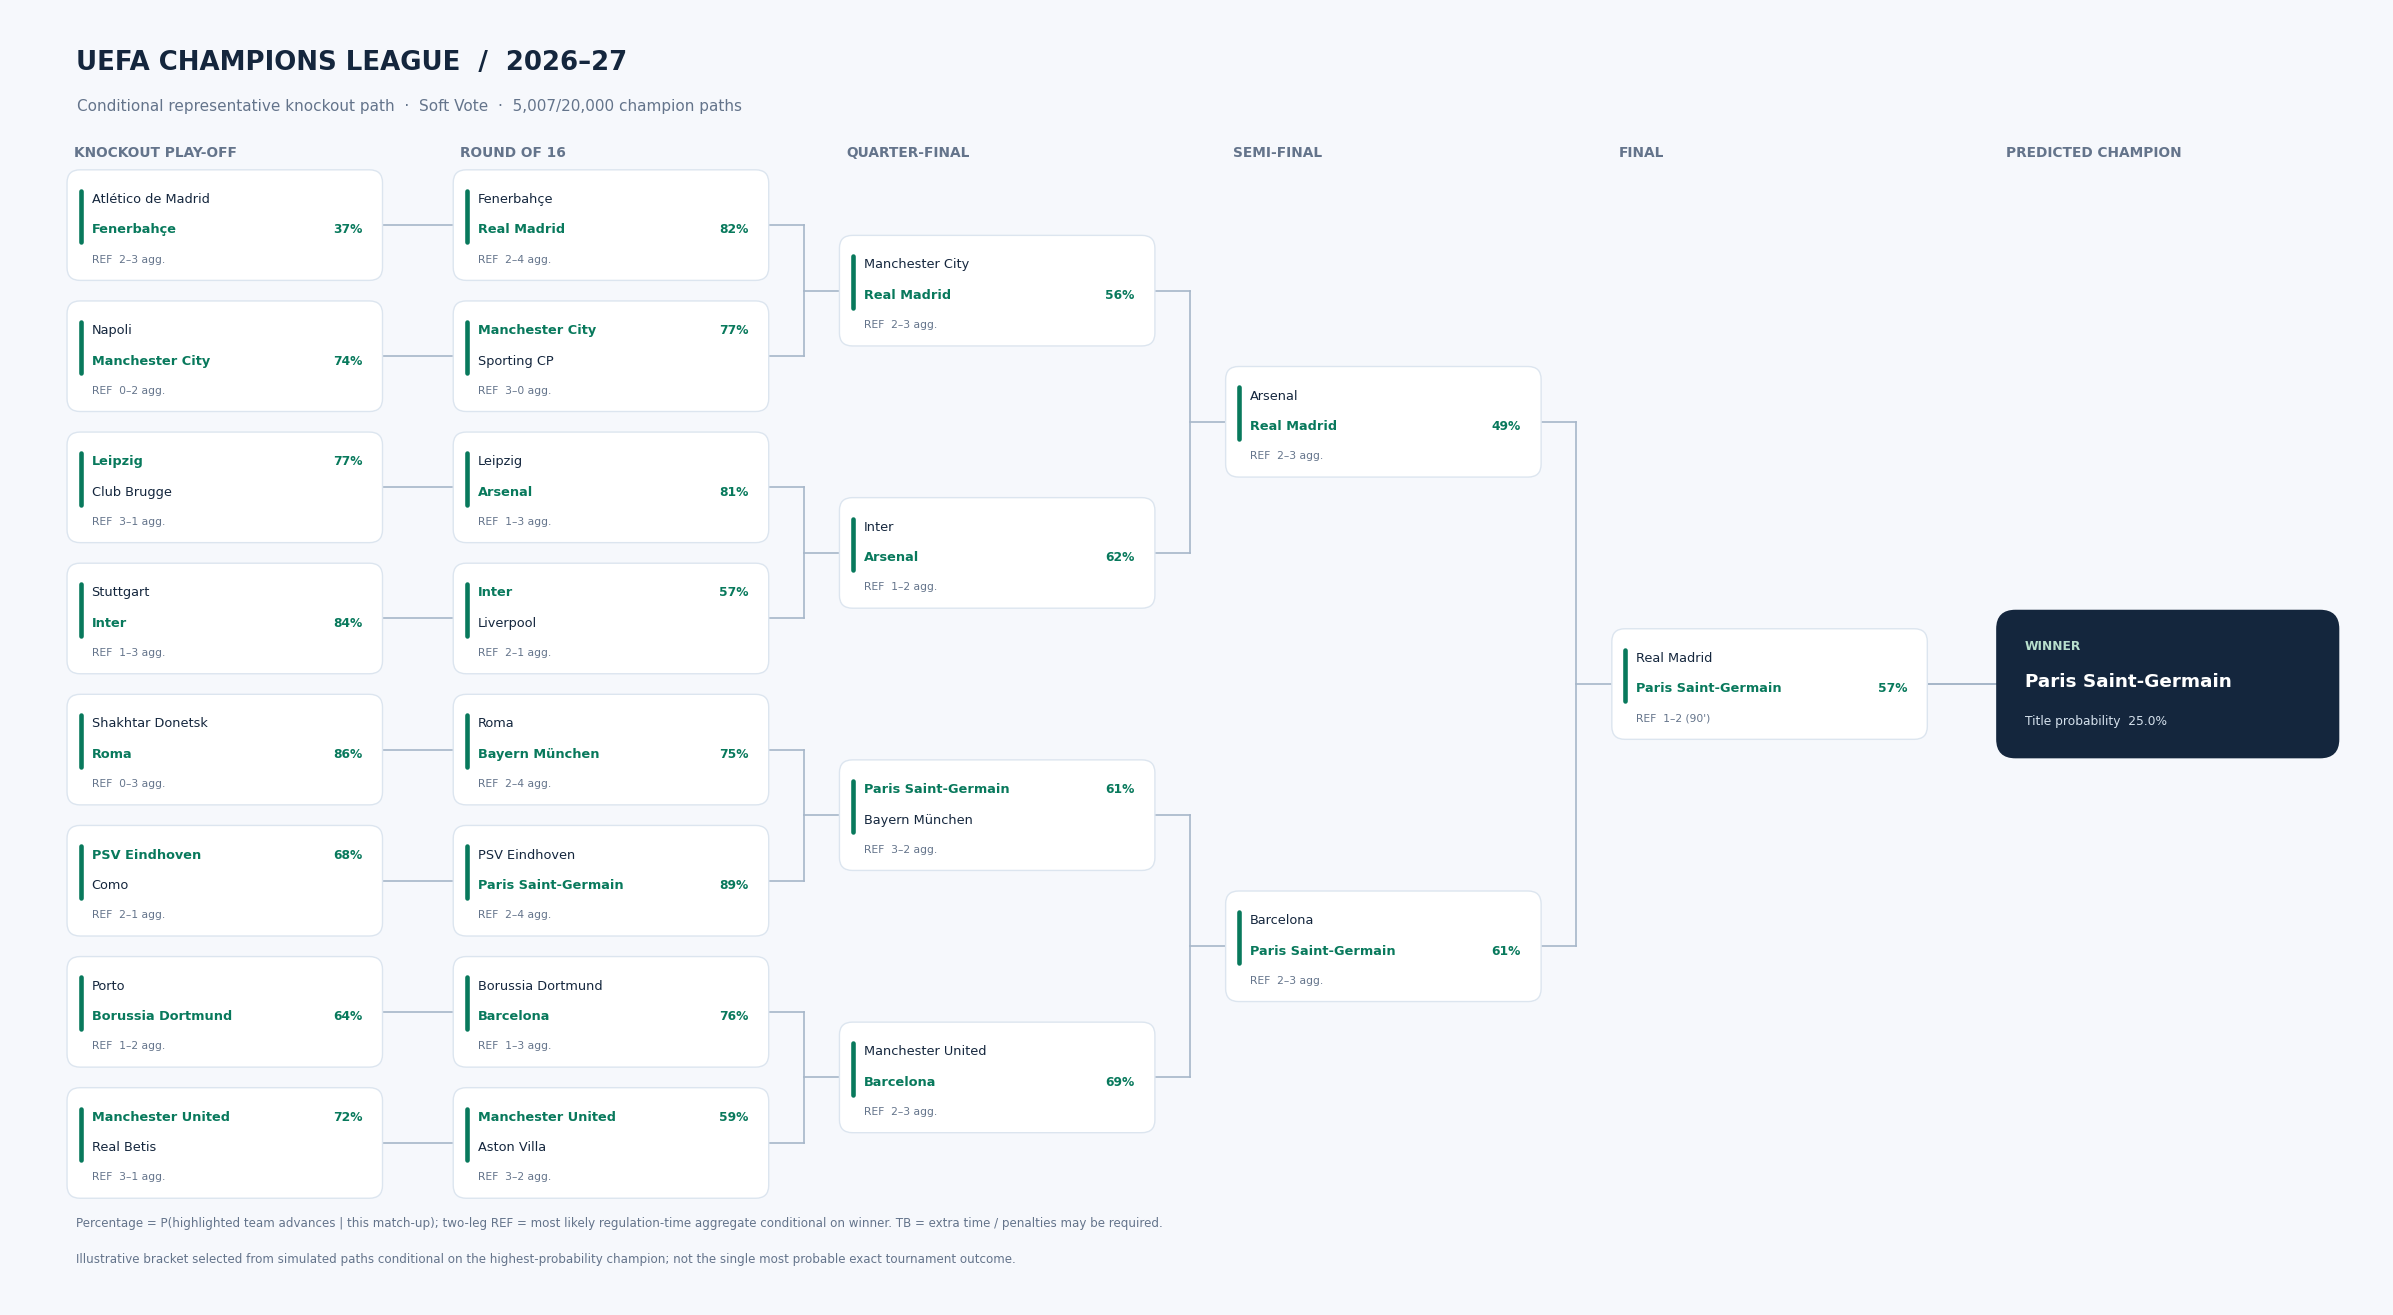

Bracket: e:\vscode-L\PYTHON_CU\DA_ML_4523\project\fifa15_fc27\model\results\ucl_2026_27_top5\representative_bracket.png
Vector graphic: e:\vscode-L\PYTHON_CU\DA_ML_4523\project\fifa15_fc27\model\results\ucl_2026_27_top5\representative_bracket.svg


In [66]:
fig, bracket_table = sim.plot_representative_knockout_bracket(
    selection=selected,
    cache=cache,
    championship_odds=results[BRACKET_METHOD]['odds']
)

png_path = OUT_DIR / 'representative_bracket.png'
svg_path = OUT_DIR / 'representative_bracket.svg'
fig.savefig(png_path, dpi=240, bbox_inches='tight', facecolor=fig.get_facecolor())
fig.savefig(svg_path, bbox_inches='tight', facecolor=fig.get_facecolor())
bracket_table.to_csv(OUT_DIR / 'representative_bracket_matches.csv', index=False)
plt.show()
print('Bracket:', png_path)
print('Vector graphic:', svg_path)

---

## Interpretation and reproducibility notes

**Held-out W/D/L evaluation (2025–26):** the model family is deliberately diverse. WDL Logistic + Club/DEF (31), Goal Difference Ridge + Club/DEF (31), and Two Goals Random Forest + Club/Position Core (61). A simple Soft Vote improves the trade-off among metrics and requires no extra meta-model; rolling Stacking / Hard Vote did not consistently justify their complexity. Always Home Win and Overall Difference Logistic remain benchmarks.

**Forecast shown:** with the 20,000-run **Soft Vote** simulation, Paris Saint-Germain was the highest-probability champion (**25.04%**, 5,007 winning paths). The representative bracket shown above is a *conditional, coherent sample path* (selected simulation index 19,413), **not** the unique maximum-likelihood entire season. Two Goals and Goal Difference respectively estimated PSG title probabilities of **20.12%** and **26.82%** in the supplied run.

**Before submission:** we should refresh the stale 2026-27 completed results, resolve official ranking and bracket edge cases, and rerun all three methods.